<a href="https://colab.research.google.com/github/annasehgal/final-project-tech-68/blob/main/Anna_TECH_68_Machine_learning_for_business_in_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Wildlife Strike Aircraft Damage Prediction

**Goal:** Predict whether a wildlife strike results in aircraft damage using flight characteristics, wildlife attributes, and environmental conditions. Compare multiple classification models and identify the factors most influential in predicting damage risk.

**Importance:** Wildlife strikes can create safety risks and costly aircraft damage. Identifying the factors associated with a higher risk of damage could help better understand which strike conditions are most consequential.

**Dataset:** FAA Wildlife Strike Database (`Public.xlsx`), containing reported wildlife strike incidents and information about the aircraft, flight conditions, wildlife involved, and resulting damage. The data was obtained from the FAA Wildlife Strike Database: https://wildlife.faa.gov/.

## Setup

### Standard imports

In [1]:
# data manipulation/analysis and fast multi-dimensional numerical array processing.
import pandas as pd
import numpy as np
# Plotting libraries
import seaborn as sns
import matplotlib.pyplot as plt

## Load and Understand the Data

In [2]:
import io
import zipfile
import requests

url = "https://wildlife.faa.gov/assets/database_excel.zip"

response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    with z.open("Public.xlsx") as f:
        df = pd.read_excel(f)

In [3]:
df.head()

,INDEX_NR,INCIDENT_DATE,INCIDENT_MONTH,INCIDENT_YEAR,TIME,TIME_OF_DAY,AIRPORT_ID,AIRPORT,LATITUDE,LONGITUDE,...,NR_INJURIES,NR_FATALITIES,COMMENTS,IMAGE,REPORTED_NAME,REPORTED_TITLE,SOURCE,PERSON,LUPDATE,TRANSFER
0,608242,1996-06-22,6,1996,NaN,NaN,KSMF,SACRAMENTO INTL,38.69542,-121.59077,...,NaN,NaN,/Legacy Record 100001/,False,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,2007-12-20,0
1,608243,1996-06-26,6,1996,NaN,NaN,KDEN,DENVER INTL AIRPORT,39.85841,-104.667,...,NaN,NaN,/Legacy Record 100002/,False,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,2007-12-20,0
2,608244,1996-07-01,7,1996,NaN,NaN,KOMA,EPPLEY AIRFIELD,41.30252,-95.89417,...,NaN,NaN,/Legacy Record 100003/,False,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,2007-12-20,0
3,608245,1996-07-01,7,1996,NaN,NaN,KIAD,WASHINGTON DULLES INTL ARPT,38.94453,-77.45581,...,NaN,NaN,/Legacy Record 100004/,False,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,2007-12-20,0
4,608246,1996-07-01,7,1996,NaN,NaN,KLGA,LA GUARDIA ARPT,40.77724,-73.87261,...,NaN,NaN,/Legacy Record 100005/,False,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,2007-12-20,0


In [4]:
print("Dataset shape:", df.shape)

Dataset shape: (361180, 102)


In [5]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

Rows: 361,180
Columns: 102


In [6]:
df.columns.tolist()

['INDEX_NR',
 'INCIDENT_DATE',
 'INCIDENT_MONTH',
 'INCIDENT_YEAR',
 'TIME',
 'TIME_OF_DAY',
 'AIRPORT_ID',
 'AIRPORT',
 'LATITUDE',
 'LONGITUDE',
 'RUNWAY',
 'STATE',
 'FAAREGION',
 'LOCATION',
 'OPID',
 'OPERATOR',
 'REG',
 'FLT',
 'AIRCRAFT',
 'AMA',
 'AMO',
 'EMA',
 'EMO',
 'AC_CLASS',
 'AC_MASS',
 'TYPE_ENG',
 'NUM_ENGS',
 'ENG_1_POS',
 'ENG_2_POS',
 'ENG_3_POS',
 'ENG_4_POS',
 'PHASE_OF_FLIGHT',
 'HEIGHT',
 'SPEED',
 'DISTANCE',
 'SKY',
 'PRECIPITATION',
 'AOS',
 'COST_REPAIRS',
 'COST_OTHER',
 'COST_REPAIRS_INFL_ADJ',
 'COST_OTHER_INFL_ADJ',
 'INGESTED_OTHER',
 'INDICATED_DAMAGE',
 'DAMAGE_LEVEL',
 'STR_RAD',
 'DAM_RAD',
 'STR_WINDSHLD',
 'DAM_WINDSHLD',
 'STR_NOSE',
 'DAM_NOSE',
 'STR_ENG1',
 'DAM_ENG1',
 'ING_ENG1',
 'STR_ENG2',
 'DAM_ENG2',
 'ING_ENG2',
 'STR_ENG3',
 'DAM_ENG3',
 'ING_ENG3',
 'STR_ENG4',
 'DAM_ENG4',
 'ING_ENG4',
 'STR_PROP',
 'DAM_PROP',
 'STR_WING_ROT',
 'DAM_WING_ROT',
 'STR_FUSE',
 'DAM_FUSE',
 'STR_LG',
 'DAM_LG',
 'STR_TAIL',
 'DAM_TAIL',
 'STR_LGHTS',


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 361180 entries, 0 to 361179
Columns: 102 entries, INDEX_NR to TRANSFER
dtypes: bool(1), float64(17), int64(41), object(43)
memory usage: 278.7+ MB


In [8]:
column_summary = pd.DataFrame({"dtype": df.dtypes, "non_null": df.notna().sum(), "missing": df.isna().sum(), "missing_pct": (df.isna().mean() * 100).round(1), "unique": df.nunique()})
column_summary

,dtype,non_null,missing,missing_pct,unique
INDEX_NR,int64,361180,0,0.0,361172
INCIDENT_DATE,object,361180,0,0.0,13374
INCIDENT_MONTH,int64,361180,0,0.0,12
INCIDENT_YEAR,int64,361180,0,0.0,37
TIME,object,239890,121290,33.6,1441
...,...,...,...,...,...
REPORTED_TITLE,object,361180,0,0.0,1
SOURCE,object,361180,0,0.0,16
PERSON,object,340093,21087,5.8,6
LUPDATE,object,361180,0,0.0,4929


In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
INDEX_NR,361180.0,1.079791e+06,4.237904e+05,608242.00,711208.75,819188.5,1506732.25,1940993.0
INCIDENT_MONTH,361180.0,7.176541e+00,2.744886e+00,1.00,5.00,7.0,9.00,12.0
INCIDENT_YEAR,361180.0,2.014303e+03,9.175313e+00,1990.00,2008.00,2016.0,2022.00,2026.0
EMO,226289.0,8.038327e+00,1.141427e+01,1.00,1.00,4.0,10.00,97.0
AC_MASS,258644.0,3.566663e+00,8.623508e-01,1.00,3.00,4.0,4.00,5.0
NUM_ENGS,258345.0,2.000890e+00,4.031844e-01,1.00,2.00,2.0,2.00,4.0
ENG_1_POS,258320.0,2.680381e+00,2.113312e+00,1.00,1.00,1.0,5.00,7.0
ENG_2_POS,240992.0,2.495900e+00,1.945138e+00,1.00,1.00,1.0,5.00,7.0
ENG_3_POS,13743.0,2.901332e+00,1.937162e+00,1.00,1.00,1.0,5.00,6.0
ENG_4_POS,3685.0,2.160923e+00,1.466748e+00,1.00,1.00,1.0,4.00,5.0


In [10]:
# since there are 102 columns, I want to understand values under each column
for col in df.columns:
    print(f"\n--- {col} ({df[col].nunique()} unique) ---")
    print(df[col].value_counts(dropna=False).head(20))


--- INDEX_NR (361172 unique) ---
INDEX_NR
793166     2
1850863    2
1520761    2
1859904    2
814615     2
1850036    2
778860     2
1861841    2
1345173    1
1345172    1
1345171    1
1345170    1
1345169    1
1345167    1
1345166    1
1345174    1
1345164    1
1345163    1
1345162    1
1345161    1
Name: count, dtype: int64

--- INCIDENT_DATE (13374 unique) ---
INCIDENT_DATE
2025-10-08    197
2025-09-26    195
2025-09-25    173
2025-10-09    169
2024-10-24    157
2025-09-28    154
2026-05-04    152
2026-07-29    151
2026-09-04    151
2024-10-07    150
2025-09-07    148
2025-09-08    148
2026-09-05    147
2025-09-27    145
2023-10-05    144
2026-08-27    143
2024-10-01    143
2026-08-17    142
2024-09-20    142
2024-09-19    141
Name: count, dtype: int64

--- INCIDENT_MONTH (12 unique) ---
INCIDENT_MONTH
8     51633
9     47520
7     47143
10    43800
5     36742
6     30952
4     26387
11    23840
3     17257
12    13394
1     11455
2     11057
Name: count, dtype: int64

--- INCIDEN

In [11]:
df.describe()

,INDEX_NR,INCIDENT_MONTH,INCIDENT_YEAR,EMO,AC_MASS,NUM_ENGS,ENG_1_POS,ENG_2_POS,ENG_3_POS,ENG_4_POS,...,STR_LGHTS,DAM_LGHTS,STR_OTHER,DAM_OTHER,OUT_OF_RANGE_SPECIES,REMAINS_COLLECTED,REMAINS_SENT,NR_INJURIES,NR_FATALITIES,TRANSFER
count,3.611800e+05,361180.000000,361180.000000,226289.000000,258644.000000,258345.000000,258320.000000,240992.000000,13743.000000,3685.000000,...,361180.000000,361180.000000,361180.000000,361180.000000,361180.000000,361180.000000,361180.000000,308.000000,25.000000,361180.0
mean,1.079791e+06,7.176541,2014.303178,8.038327,3.566663,2.000890,2.680381,2.495900,2.901332,2.160923,...,0.004552,0.002999,0.140431,0.007221,0.001094,0.544114,0.185977,1.279221,2.080000,0.0
std,4.237904e+05,2.744886,9.175313,11.414271,0.862351,0.403184,2.113312,1.945138,1.937162,1.466748,...,0.067313,0.054677,0.347434,0.084668,0.033052,0.498051,0.389088,0.660636,1.630951,0.0
min,6.082420e+05,1.000000,1990.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.0
25%,7.112088e+05,5.000000,2008.000000,1.000000,3.000000,2.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.0
50%,8.191885e+05,7.000000,2016.000000,4.000000,4.000000,2.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,2.000000,0.0
75%,1.506732e+06,9.000000,2022.000000,10.000000,4.000000,2.000000,5.000000,5.000000,5.000000,4.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,2.000000,0.0
max,1.940993e+06,12.000000,2026.000000,97.000000,5.000000,4.000000,7.000000,7.000000,6.000000,5.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,7.000000,8.000000,0.0


In [12]:
# see all values
for col in df.columns:
    print(f"\n--- {col} ({df[col].nunique()} unique) ---")
    print(df[col].value_counts(dropna=False))


--- INDEX_NR (361172 unique) ---
INDEX_NR
793166     2
1850863    2
1520761    2
1859904    2
814615     2
          ..
743787     1
743786     1
743785     1
743784     1
743797     1
Name: count, Length: 361172, dtype: int64

--- INCIDENT_DATE (13374 unique) ---
INCIDENT_DATE
2025-10-08    197
2025-09-26    195
2025-09-25    173
2025-10-09    169
2024-10-24    157
             ... 
2026-10-25      1
2026-10-14      1
2026-10-01      1
2026-10-10      1
2026-11-08      1
Name: count, Length: 13374, dtype: int64

--- INCIDENT_MONTH (12 unique) ---
INCIDENT_MONTH
8     51633
9     47520
7     47143
10    43800
5     36742
6     30952
4     26387
11    23840
3     17257
12    13394
1     11455
2     11057
Name: count, dtype: int64

--- INCIDENT_YEAR (37 unique) ---
INCIDENT_YEAR
2025    24457
2024    22370
2023    19623
2026    17608
2019    17345
2022    17223
2018    16206
2021    15642
2017    14754
2015    13777
2014    13690
2016    13380
2020    11627
2013    11405
2012    10937
2

# Pre-process, cleaning and EDA

`INDEX_NR` has 361,172 unique values across 361,180 rows, so we check for repeated IDs.

In [13]:
df[df["INDEX_NR"].duplicated(keep=False)].sort_values("INDEX_NR")

,INDEX_NR,INCIDENT_DATE,INCIDENT_MONTH,INCIDENT_YEAR,TIME,TIME_OF_DAY,AIRPORT_ID,AIRPORT,LATITUDE,LONGITUDE,...,NR_INJURIES,NR_FATALITIES,COMMENTS,IMAGE,REPORTED_NAME,REPORTED_TITLE,SOURCE,PERSON,LUPDATE,TRANSFER
152290,778860,2016-03-01,3,2016,NaN,NaN,KPSM,PORTSMOUTH INTL ARPT AT PEASE,43.07796,-70.82327,...,NaN,NaN,2016-3-1-211917 /Legacy Record 371717/,False,REDACTED,REDACTED,FAA Form 5200-7-E,Carcass Found,2016-09-01,0
152291,778860,2016-03-01,3,2016,NaN,NaN,KPSM,PORTSMOUTH INTL ARPT AT PEASE,43.07796,-70.82327,...,NaN,NaN,2016-3-1-211917 /Legacy Record 371717/,False,REDACTED,REDACTED,FAA Form 5200-7-E,Carcass Found,2016-09-01,0
162193,793166,2017-04-29,4,2017,NaN,NaN,KNUQ,MOFFETT FEDERAL AIRFIELD,37.41614,-122.04914,...,NaN,NaN,2017-6-12-173440 /Legacy Record 390497/,False,REDACTED,REDACTED,FAA Form 5200-7-E,Carcass Found,2018-05-18,0
162194,793166,2017-04-29,4,2017,NaN,NaN,KNUQ,MOFFETT FEDERAL AIRFIELD,37.41614,-122.04914,...,NaN,NaN,2017-6-12-173440 /Legacy Record 390497/,False,REDACTED,REDACTED,FAA Form 5200-7-E,Carcass Found,2018-05-18,0
177224,814615,2018-09-27,9,2018,NaN,NaN,KBDL,BRADLEY INTL,41.93887,-72.68323,...,NaN,NaN,2018-9-28-111208 /Legacy Record 416060/,False,REDACTED,REDACTED,FAA Form 5200-7-E,Carcass Found,2018-11-27,0
177225,814615,2018-09-27,9,2018,NaN,NaN,KBDL,BRADLEY INTL,41.93887,-72.68323,...,NaN,NaN,2018-9-28-111208 /Legacy Record 416060/,False,REDACTED,REDACTED,FAA Form 5200-7-E,Carcass Found,2018-11-27,0
277917,1520761,2017-03-04,3,2017,NaN,NaN,KISN,SLOULIN FLD INTL ARPT,48.17794,-103.64235,...,NaN,NaN,NaN,False,REDACTED,REDACTED,FAA Form 5200-7-E,Carcass Found,2024-05-15,0
277918,1520761,2017-03-04,3,2017,NaN,NaN,KISN,SLOULIN FLD INTL ARPT,48.17794,-103.64235,...,NaN,NaN,NaN,False,REDACTED,REDACTED,FAA Form 5200-7-E,Carcass Found,2024-05-15,0
343496,1850036,2026-02-13,2,2026,,NaN,KPAO,PALO ALTO ARPT OF SANTA CLARA COUNTY,37.46112,-122.11504,...,NaN,NaN,revised species,False,REDACTED,REDACTED,FAA Form 5200-7-E,Carcass Found,2026-05-29,0
343497,1850036,2026-02-13,2,2026,,NaN,KPAO,PALO ALTO ARPT OF SANTA CLARA COUNTY,37.46112,-122.11504,...,NaN,NaN,revised species,False,REDACTED,REDACTED,FAA Form 5200-7-E,Carcass Found,2026-05-29,0


In [14]:
df.duplicated().sum()

np.int64(0)

Since there are no duplicated `INDEX_NR` there are no identical rows in the dataset.

In [15]:
df["INDICATED_DAMAGE"].value_counts()

,count
INDICATED_DAMAGE,
0,338813
1,22367


In [16]:
df["INDICATED_DAMAGE"].value_counts(normalize=True)

,proportion
INDICATED_DAMAGE,
0,0.938072
1,0.061928


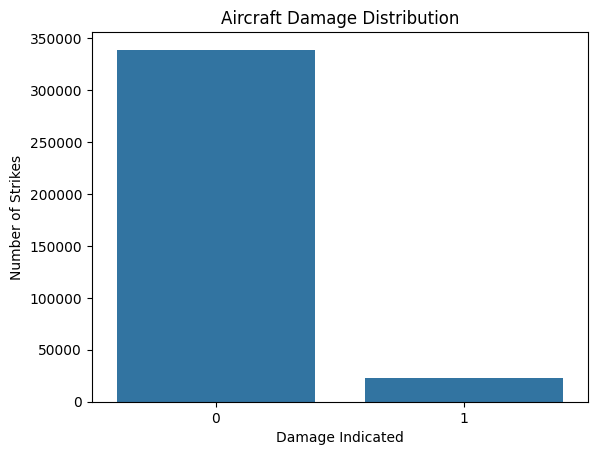

In [17]:
sns.countplot(data=df, x="INDICATED_DAMAGE")
plt.title("Aircraft Damage Distribution")
plt.xlabel("Damage Indicated")
plt.ylabel("Number of Strikes")
plt.show()

### Aircraft Damage

`INDICATED_DAMAGE` is the target variable for this project, where 1 indicates reported aircraft damage and 0 indicates no reported damage.

Only 22,367 of 361,180 reported strikes (about 6.2%) indicate aircraft damage, so the target is highly imbalanced. Because most strikes do not result in damage, accuracy alone may be misleading when evaluating classification models.

Analyze which columns are relevant to the problem and drop extra ones.

In [18]:
with pd.option_context("display.max_rows", None):
    display(column_summary)

,dtype,non_null,missing,missing_pct,unique
INDEX_NR,int64,361180,0,0.0,361172
INCIDENT_DATE,object,361180,0,0.0,13374
INCIDENT_MONTH,int64,361180,0,0.0,12
INCIDENT_YEAR,int64,361180,0,0.0,37
TIME,object,239890,121290,33.6,1441
TIME_OF_DAY,object,203317,157863,43.7,4
AIRPORT_ID,object,361180,0,0.0,2811
AIRPORT,object,361180,0,0.0,2811
LATITUDE,object,312090,49090,13.6,2802
LONGITUDE,object,312084,49096,13.6,2803


### Feature Selection

The FAA dataset contains 102 columns. I selected 16 features describing wildlife, aircraft, flight conditions, location, and environmental characteristics to predict whether a wildlife strike resulted in aircraft damage.

The target variable is `INDICATED_DAMAGE`, where 0 represents no reported damage and 1 represents reported damage.

Identifiers, redundant fields, administrative information, and damage-related outcomes were excluded to reduce unnecessary complexity and avoid data leakage. The selected features will be evaluated and refined during modeling.

In [19]:
target = "INDICATED_DAMAGE"

In [20]:
selected_features = ["INCIDENT_MONTH", "TIME_OF_DAY", "FAAREGION", "SKY", "PHASE_OF_FLIGHT", "HEIGHT", "SPEED", "DISTANCE", "AC_CLASS", "AC_MASS", "TYPE_ENG", "NUM_ENGS", "SIZE", "NUM_SEEN", "NUM_STRUCK", "WARNED"]

In [21]:
X = df[selected_features].copy()
y = df["INDICATED_DAMAGE"].copy()

In [22]:
print("Features:", X.shape)
print("Target:", y.shape)

Features: (361180, 16)
Target: (361180,)


In [23]:
print(y.value_counts())
print("\nDamage percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

INDICATED_DAMAGE
0    338813
1     22367
Name: count, dtype: int64

Damage percentages:
INDICATED_DAMAGE
0    93.81
1     6.19
Name: proportion, dtype: float64


The target variable is imbalanced, with approximately 6% of reported wildlife strikes indicating aircraft damage. This imbalance will be considered during model training and evaluation, since accuracy alone may not adequately reflect the model's ability to identify damaging strikes.

### Preprocessing Selected Features

After selecting the relevant features, I examine their missing values and data types before training the models. Missing numerical values will be imputed, while categorical features will be encoded into numerical representations that machine learning models can process.

In [24]:
print("Missing values:")
print(X.isna().sum())

print("\nData types:")
print(X.dtypes)

Missing values:
INCIDENT_MONTH          0
TIME_OF_DAY        157863
FAAREGION           49090
SKY                193964
PHASE_OF_FLIGHT    143145
HEIGHT             182886
SPEED              250511
DISTANCE           121499
AC_CLASS           102387
AC_MASS            102536
TYPE_ENG           102857
NUM_ENGS           102835
SIZE                43210
NUM_SEEN           246396
NUM_STRUCK            760
WARNED                  0
dtype: int64

Data types:
INCIDENT_MONTH       int64
TIME_OF_DAY         object
FAAREGION           object
SKY                 object
PHASE_OF_FLIGHT     object
HEIGHT             float64
SPEED              float64
DISTANCE           float64
AC_CLASS            object
AC_MASS            float64
TYPE_ENG            object
NUM_ENGS           float64
SIZE                object
NUM_SEEN            object
NUM_STRUCK          object
WARNED              object
dtype: object


In [25]:
# Replace blank strings with missing values
X = X.replace(r"^\s*$", np.nan, regex=True)

In [26]:
# Categorical features
categorical_features = [
    "INCIDENT_MONTH", "TIME_OF_DAY", "FAAREGION",
    "SKY", "PHASE_OF_FLIGHT", "AC_CLASS",
    "AC_MASS", "TYPE_ENG", "SIZE",
    "NUM_SEEN", "NUM_STRUCK", "WARNED"
]

In [27]:
# Treat numeric category codes as categories
X["INCIDENT_MONTH"] = X["INCIDENT_MONTH"].astype(str)
X["AC_MASS"] = X["AC_MASS"].astype("Int64").astype("string")

1. Check whether missingness relates to damage

In [28]:
missing_by_damage = X.isna().groupby(y).mean().mul(100).round(1).T
missing_by_damage.columns = ["No Damage (%)", "Damage (%)"]
missing_by_damage

,No Damage (%),Damage (%)
INCIDENT_MONTH,0.0,0.0
TIME_OF_DAY,45.4,18.7
FAAREGION,13.1,20.6
SKY,55.2,30.6
PHASE_OF_FLIGHT,41.5,12.0
HEIGHT,52.3,24.8
SPEED,71.0,44.4
DISTANCE,32.4,52.6
AC_CLASS,30.1,1.3
AC_MASS,30.2,0.9


2. Check whether aircraft information is missing together

In [29]:
aircraft_cols = ["AC_CLASS", "AC_MASS", "TYPE_ENG", "NUM_ENGS"]
X[aircraft_cols].isna().sum(axis=1).value_counts().sort_index()

,count
0,258183
1,100
2,186
3,701
4,102010


3. Inspect numeric values before imputing

In [30]:
X[["HEIGHT", "SPEED", "DISTANCE", "NUM_ENGS"]].describe()

,HEIGHT,SPEED,DISTANCE,NUM_ENGS
count,178294.000000,110669.000000,239681.000000,258345.000000
mean,878.572577,143.088832,0.880415,2.000890
std,1853.703739,46.574920,3.692035,0.403184
min,0.000000,0.000000,0.000000,1.000000
25%,0.000000,120.000000,0.000000,2.000000
50%,50.000000,140.000000,0.000000,2.000000
75%,1000.000000,160.000000,0.000000,2.000000
max,32000.000000,1000.000000,99.000000,4.000000


### Missing Data Analysis

Missing values are not distributed equally between damaging and non-damaging wildlife strikes. Aircraft and flight characteristics are generally more complete in damaging-strike reports, suggesting that reporting patterns may influence the available information.

Additionally, aircraft characteristics are frequently missing together, with 102,090 records missing all four selected aircraft attributes.

To preserve the dataset without inventing aircraft or environmental information, missing categorical values will be represented as unknown. Numerical variables will be handled through imputation and missingness indicators fitted using the training data. This approach retains incomplete records while acknowledging that missingness itself may influence model predictions.

In [31]:
X.loc[X["SPEED"] > 400, ["SPEED", "HEIGHT", "PHASE_OF_FLIGHT"]].sort_values("SPEED", ascending=False).head(20)

,SPEED,HEIGHT,PHASE_OF_FLIGHT
357199,1000.0,500.0,En Route
262591,541.0,32000.0,Descent
360139,500.0,6000.0,Approach


In [32]:
df.loc[df["SPEED"] > 400, ["INCIDENT_DATE", "AIRCRAFT", "SPEED", "HEIGHT", "PHASE_OF_FLIGHT", "REMARKS"]]

,INCIDENT_DATE,AIRCRAFT,SPEED,HEIGHT,PHASE_OF_FLIGHT,REMARKS
262591,2023-09-14,B-737-900,541.0,32000.0,Descent,"Snarge on nose and windshield. 737-924ER, Engi..."
357199,2026-08-03,AEROS 350,1000.0,500.0,En Route,DEPARTMENT OF HOMELAND SECURITY Unknown bird ...
360139,2026-08-31,B-737-7,500.0,6000.0,Approach,"SWA2127 reported strike after landing, no bird..."


### Outlier Inspection

A boxplot was used to examine the distribution of aircraft speed and identify unusually high values. Three observations exceeded 400, with a maximum recorded speed of 1,000.

Since these values could not be confirmed as errors, all observations were retained for modeling.

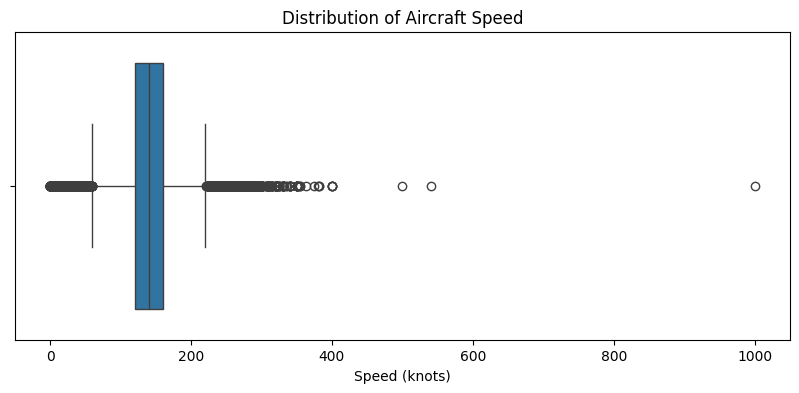

In [33]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=X["SPEED"])
plt.title("Distribution of Aircraft Speed")
plt.xlabel("Speed (knots)")
plt.show()

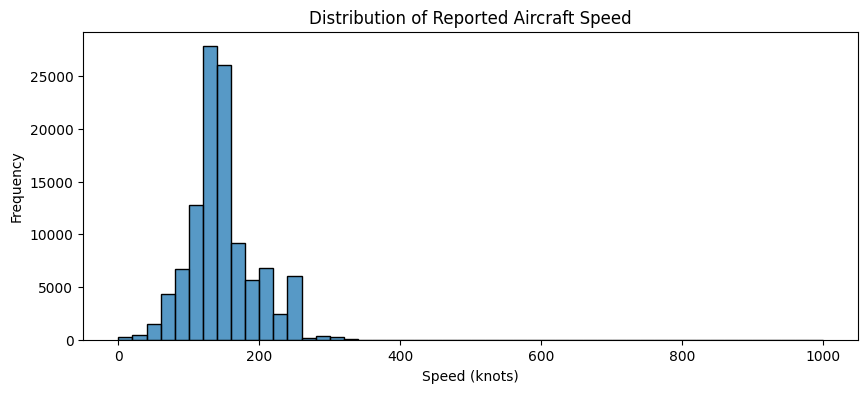

In [34]:
plt.figure(figsize=(10, 4))
sns.histplot(X["SPEED"].dropna(), bins=50)
plt.title("Distribution of Reported Aircraft Speed")
plt.xlabel("Speed (knots)")
plt.ylabel("Frequency")
plt.show()

The distribution of reported aircraft speeds is right-skewed, with most observations concentrated between approximately 100 and 200 knots. The boxplot identifies several high-speed outliers, including three observations above 400 knots.

Because these values could not be confirmed as data-entry errors, they were retained. No observations were removed during outlier inspection.

In [35]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 361180 entries, 0 to 361179
Data columns (total 16 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   INCIDENT_MONTH   361180 non-null  object 
 1   TIME_OF_DAY      203317 non-null  object 
 2   FAAREGION        312090 non-null  object 
 3   SKY              167216 non-null  object 
 4   PHASE_OF_FLIGHT  218035 non-null  object 
 5   HEIGHT           178294 non-null  float64
 6   SPEED            110669 non-null  float64
 7   DISTANCE         239681 non-null  float64
 8   AC_CLASS         258793 non-null  object 
 9   AC_MASS          258644 non-null  string 
 10  TYPE_ENG         258323 non-null  object 
 11  NUM_ENGS         258345 non-null  float64
 12  SIZE             317970 non-null  object 
 13  NUM_SEEN         114784 non-null  object 
 14  NUM_STRUCK       360420 non-null  object 
 15  WARNED           361180 non-null  object 
dtypes: float64(4), object(11), string(1)
m

In [36]:
X.head()

,INCIDENT_MONTH,TIME_OF_DAY,FAAREGION,SKY,PHASE_OF_FLIGHT,HEIGHT,SPEED,DISTANCE,AC_CLASS,AC_MASS,TYPE_ENG,NUM_ENGS,SIZE,NUM_SEEN,NUM_STRUCK,WARNED
0,6,NaN,AWP,NaN,Take-off Run,0.0,NaN,0.0,A,4,D,2.0,Medium,NaN,1,Unknown
1,6,NaN,ANM,NaN,Take-off Run,0.0,NaN,0.0,A,4,D,2.0,Medium,NaN,1,Unknown
2,7,NaN,ACE,NaN,Take-off Run,0.0,NaN,0.0,A,4,D,2.0,Medium,NaN,1,Unknown
3,7,NaN,AEA,NaN,Approach,1000.0,NaN,NaN,A,4,D,2.0,Medium,NaN,1,Unknown
4,7,NaN,AEA,NaN,Climb,5000.0,NaN,NaN,A,4,D,2.0,Medium,NaN,1,Unknown


In [37]:
for col in X.columns:
    print(f"\n--- {col} ---")
    print(X[col].value_counts(dropna=False))


--- INCIDENT_MONTH ---
INCIDENT_MONTH
8     51633
9     47520
7     47143
10    43800
5     36742
6     30952
4     26387
11    23840
3     17257
12    13394
1     11455
2     11057
Name: count, dtype: int64

--- TIME_OF_DAY ---
TIME_OF_DAY
NaN      157863
Day      124232
Night     63289
Dusk       8900
Dawn       6896
Name: count, dtype: int64

--- FAAREGION ---
FAAREGION
ASO    68557
NaN    49090
AGL    48665
AEA    47370
ASW    43159
AWP    37936
ANM    32934
ACE    14424
ANE    11368
FGN     5948
AAL     1729
Name: count, dtype: int64

--- SKY ---
SKY
NaN           193964
No Cloud       81698
Some Cloud     57733
Overcast       27785
Name: count, dtype: int64

--- PHASE_OF_FLIGHT ---
PHASE_OF_FLIGHT
NaN             143145
Approach         92204
Landing Roll     40019
Take-off Run     36154
Climb            31772
En Route          6499
Departure         4390
Descent           3138
Local             1570
Arrival           1287
Taxi               877
Parked             118
Unknown   

## Visualize damage rates across features

In [38]:
damage_by_size = df.groupby("SIZE")["INDICATED_DAMAGE"].mean().mul(100).sort_values(ascending=False)

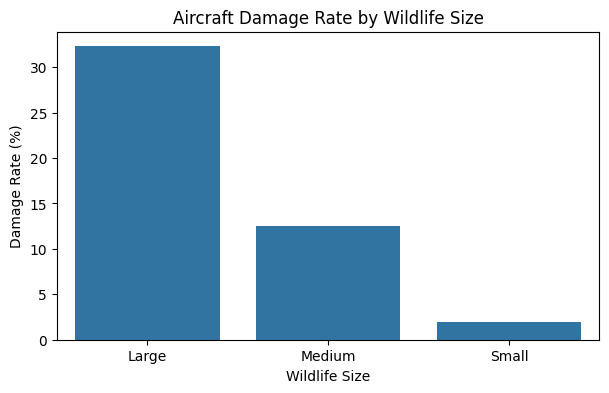

In [39]:
plt.figure(figsize=(7, 4))
sns.barplot(x=damage_by_size.index, y=damage_by_size.values)
plt.title("Aircraft Damage Rate by Wildlife Size")
plt.xlabel("Wildlife Size")
plt.ylabel("Damage Rate (%)")
plt.show()

## Damage rate by flight phase

In [40]:
damage_by_phase = df.groupby("PHASE_OF_FLIGHT")["INDICATED_DAMAGE"].mean().mul(100).sort_values(ascending=False)

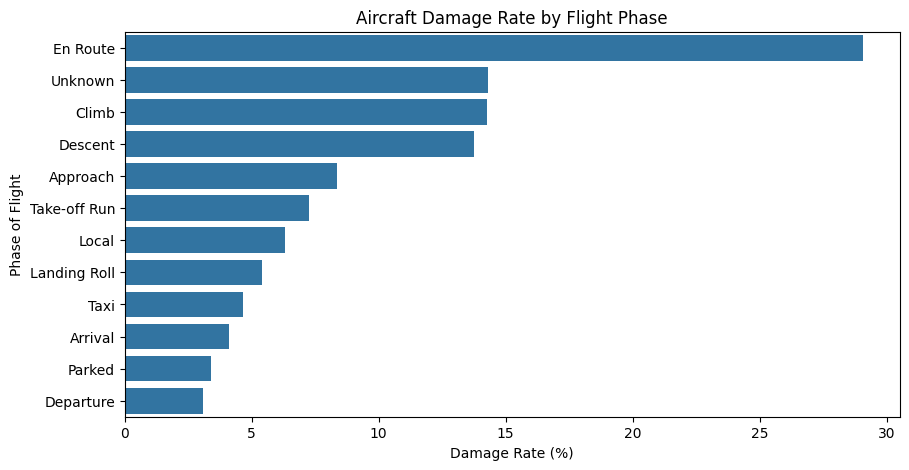

In [41]:
plt.figure(figsize=(10, 5))
sns.barplot(x=damage_by_phase.values, y=damage_by_phase.index)
plt.title("Aircraft Damage Rate by Flight Phase")
plt.xlabel("Damage Rate (%)")
plt.ylabel("Phase of Flight")
plt.show()

## Visualize missingness across all selected features

In [42]:
missing_pct = X.isna().mean().mul(100).sort_values()

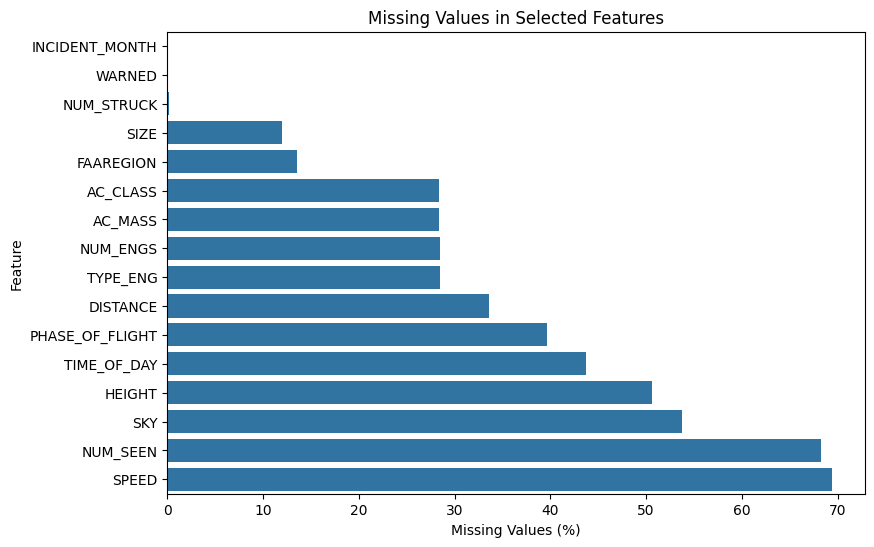

In [43]:
plt.figure(figsize=(9, 6))
sns.barplot(x=missing_pct.values, y=missing_pct.index)
plt.title("Missing Values in Selected Features")
plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.show()

### Exploratory Analysis Findings

Wildlife size and flight phase show noticeable differences in reported aircraft damage rates. Large wildlife strikes have the highest damage rate among the size categories, while en-route strikes have the highest damage rate among recorded flight phases.

Several selected features also contain substantial missing information. To avoid discarding observations, missing values will be addressed during preprocessing rather than removing incomplete records.

## Prepare the data

### Data Preparation Decisions

After examining the selected features, their missing values, and their relationships with aircraft damage, the following decisions were made:

- **Feature selection:** `AC_CLASS` was excluded because most recorded values belong to one category, while `NUM_SEEN` was excluded because approximately 68% of its values are missing. The remaining 14 features were retained for initial modeling.
- **Categorical variables:** Missing values in features such as `TIME_OF_DAY`, `FAAREGION`, `SKY`, and `PHASE_OF_FLIGHT` will be represented as `"Unknown"` rather than assuming a particular condition.
- **Aircraft characteristics:** `AC_MASS` and `NUM_ENGS` will be treated as categorical variables. Missing values will not be replaced with assumed aircraft characteristics.
- **Numerical variables:** `HEIGHT`, `SPEED`, and `DISTANCE` will remain numerical. Missing values will be handled through median imputation and missingness indicators.
- **Outliers:** Unusually high aircraft speeds were inspected but retained because they could not be confirmed as errors.
- **Class imbalance:** Only 6.19% of records report aircraft damage. Stratified splitting will preserve this distribution, and class weighting will be considered during model training.

To prevent data leakage, numerical imputation and categorical encoding will be fitted using training data only. No observations will be removed solely because they contain missing values.

There for 14 features are:

In [44]:
selected_features = [
    "INCIDENT_MONTH", "TIME_OF_DAY", "FAAREGION", "SKY",
    "PHASE_OF_FLIGHT", "HEIGHT", "SPEED", "DISTANCE",
    "AC_MASS", "TYPE_ENG", "NUM_ENGS", "SIZE",
    "NUM_STRUCK", "WARNED"
]

In [45]:
X = df[selected_features].copy()
y = df["INDICATED_DAMAGE"].copy()

In [46]:
print("Features:", X.shape)
print("Target:", y.shape)

Features: (361180, 14)
Target: (361180,)


**Prepare categorical values**

In [47]:
numeric_cols = ["HEIGHT", "SPEED", "DISTANCE"]
categorical_cols = X.columns.difference(numeric_cols).tolist()

standardize categorical values:

In [48]:
X[categorical_cols] = X[categorical_cols].astype("string")
X[categorical_cols] = X[categorical_cols].apply(lambda col: col.str.strip()).replace("", pd.NA)
X[categorical_cols] = X[categorical_cols].fillna("Unknown").astype(str)

In [49]:
X[categorical_cols].isna().sum()

,0
AC_MASS,0
FAAREGION,0
INCIDENT_MONTH,0
NUM_ENGS,0
NUM_STRUCK,0
PHASE_OF_FLIGHT,0
SIZE,0
SKY,0
TIME_OF_DAY,0
TYPE_ENG,0


### Exploring Factors Associated with Aircraft Damage

The previous exploratory analysis examined the distribution of aircraft damage, missing values, and numerical outliers. Two research questions were also investigated:

1. **Does wildlife size relate to the likelihood of aircraft damage?** The analysis showed that larger wildlife was associated with a higher percentage of damaging strikes.
2. **Does aircraft damage vary by phase of flight?** Damage rates differed across flight phases, with en-route incidents showing the highest observed percentage among recorded phases.

Building on these findings, the following questions explore additional factors that may be associated with aircraft damage.

3. **Does the month of a wildlife strike relate to the likelihood of aircraft damage?**
4. **Does the number of animals struck relate to the likelihood of aircraft damage?**

These analyses compare damage rates across categories rather than total strike counts. The findings will help us interpret the selected features before building classification models.

#### Question 3: Does aircraft damage vary by month?

Wildlife strikes occur throughout the year, but their frequency and severity may vary seasonally. This analysis examines the percentage of reported strikes that resulted in aircraft damage during each month.

In [50]:
damage_by_month = df.groupby("INCIDENT_MONTH")["INDICATED_DAMAGE"].mean().mul(100).sort_index()

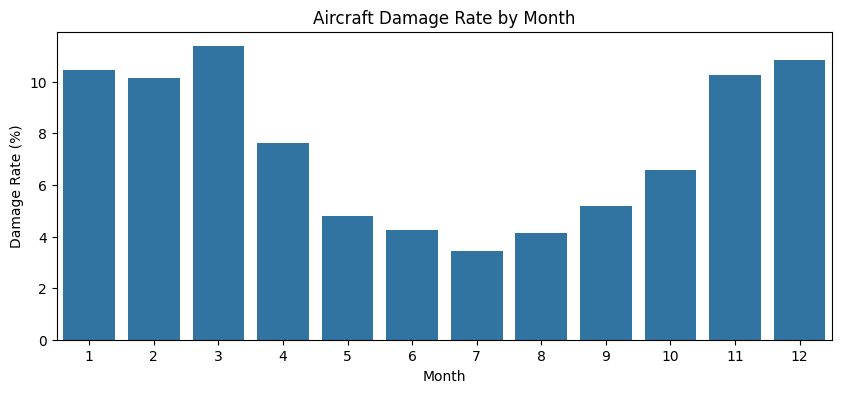

In [51]:
plt.figure(figsize=(10, 4))
sns.barplot(x=damage_by_month.index, y=damage_by_month.values)
plt.title("Aircraft Damage Rate by Month")
plt.xlabel("Month")
plt.ylabel("Damage Rate (%)")
plt.show()

**Finding:** Aircraft damage rates vary across months. March has the highest observed damage rate (11.37%), while July has the lowest (3.43%). Although wildlife strikes are more frequent during the summer, a smaller proportion of these incidents report aircraft damage.

This suggests that strike frequency and damage severity follow different seasonal patterns. These differences may reflect changes in wildlife activity, species, or flight conditions, but the analysis does not establish their causes.

#### Question 4: Does the number of animals struck relate to aircraft damage?

Strikes involving multiple animals may have different damage outcomes than strikes involving a single animal. This analysis compares the percentage of damaging incidents across the recorded number-of-animals-struck categories.

In [52]:
struck_order = ["1", "2-10", "11-100", "More than 100"]
damage_by_struck = df.assign(NUM_STRUCK=df["NUM_STRUCK"].astype("string")).groupby("NUM_STRUCK")["INDICATED_DAMAGE"].mean().mul(100).reindex(struck_order)

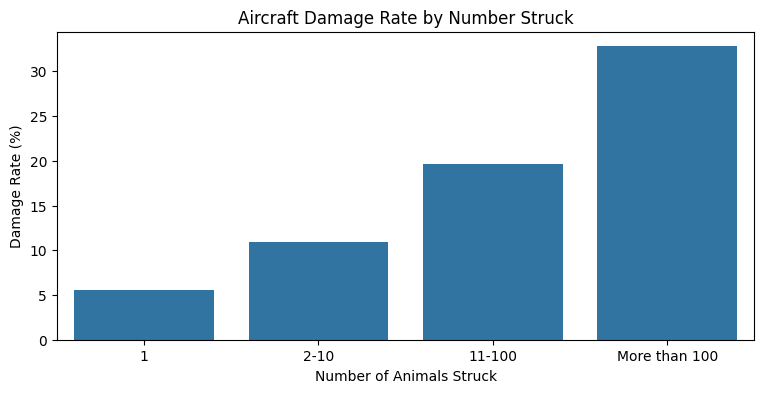

In [53]:
plt.figure(figsize=(9, 4))
sns.barplot(x=damage_by_struck.index, y=damage_by_struck.values)
plt.title("Aircraft Damage Rate by Number Struck")
plt.xlabel("Number of Animals Struck")
plt.ylabel("Damage Rate (%)")
plt.show()

In [54]:
df.assign(NUM_STRUCK=df["NUM_STRUCK"].astype("string")).groupby("NUM_STRUCK")["INDICATED_DAMAGE"].agg(["count", "sum", "mean"]).reindex(struck_order)

,count,sum,mean
NUM_STRUCK,,,
1,322102,17882,0.055517
2-10,36561,4002,0.109461
11-100,1696,333,0.196344
More than 100,61,20,0.327869


**Finding:** The percentage of reported incidents involving aircraft damage increases with the number of animals struck. Single-animal strikes have a damage rate of 5.55%, compared with 10.94% for 2-10 animals, 19.63% for 11-100 animals, and 32.79% for more than 100 animals.

This suggests that strikes involving multiple animals are associated with a greater likelihood of reported aircraft damage. However, the largest category contains only 61 incidents, so its damage rate should be interpreted cautiously.

Check the category counts

In [55]:
df.groupby("INCIDENT_MONTH")["INDICATED_DAMAGE"].agg(["count", "sum", "mean"])

,count,sum,mean
INCIDENT_MONTH,,,
1,11455,1198,0.104583
2,11057,1122,0.101474
3,17257,1962,0.113693
4,26387,2011,0.076212
5,36742,1760,0.047902
6,30952,1318,0.042582
7,47143,1615,0.034257
8,51633,2141,0.041466
9,47520,2465,0.051873


In [56]:
df.assign(NUM_STRUCK=df["NUM_STRUCK"].astype("string")).groupby("NUM_STRUCK")["INDICATED_DAMAGE"].agg(["count", "sum", "mean"]).reindex(struck_order)

,count,sum,mean
NUM_STRUCK,,,
1,322102,17882,0.055517
2-10,36561,4002,0.109461
11-100,1696,333,0.196344
More than 100,61,20,0.327869


### EDA Summary

The exploratory analysis identified several factors associated with reported aircraft damage. Larger wildlife, certain phases of flight, and strikes involving multiple animals showed higher damage rates. Damage rates also varied by month, with higher percentages during winter and early spring than during summer.

The dataset contains substantial missing information in several features, particularly aircraft speed and number of animals seen. The target variable is also imbalanced, with only 6.19% of reported strikes indicating damage.

These findings support the selected features and highlight the importance of handling missing values and class imbalance carefully during modeling. The observed relationships are associations and do not establish causation.

### Train-Test Split

The dataset is divided into 80% training data and 20% testing data. Stratified sampling is used to preserve the proportion of damaging and non-damaging wildlife strikes in both sets.

The test data will be reserved for evaluating model performance on unseen observations.

In [57]:
from sklearn.model_selection import train_test_split

In [58]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training:", X_train.shape, y_train.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (288944, 14) (288944,)
Testing: (72236, 14) (72236,)


In [59]:
print("Training damage rate:", round(y_train.mean() * 100, 2), "%")
print("Testing damage rate:", round(y_test.mean() * 100, 2), "%")

Training damage rate: 6.19 %
Testing damage rate: 6.19 %


### Missing Values and Feature Encoding

Numerical missing values are replaced using the median of each feature from the training set. Missingness indicators are included to preserve information about which values were originally absent.

Categorical features are transformed using one-hot encoding, while numerical features are standardized. Preprocessing is fitted on the training data and then applied to the test data to prevent data leakage.

In [60]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [61]:
numeric_cols = ["HEIGHT", "SPEED", "DISTANCE"]
categorical_cols = X.columns.difference(numeric_cols).tolist()

In [62]:
categorical_cols

['AC_MASS',
 'FAAREGION',
 'INCIDENT_MONTH',
 'NUM_ENGS',
 'NUM_STRUCK',
 'PHASE_OF_FLIGHT',
 'SIZE',
 'SKY',
 'TIME_OF_DAY',
 'TYPE_ENG',
 'WARNED']

In [63]:
numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler())
])

Categorical preprocessing

In [64]:
categorical_preprocessor = OneHotEncoder(handle_unknown="ignore")

Combine preprocessing

In [65]:
preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numeric_cols),
    ("categorical", categorical_preprocessor, categorical_cols)
])

Apply preprocessing

In [66]:
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

In [67]:
print("Prepared training data:", X_train_prepared.shape)
print("Prepared testing data:", X_test_prepared.shape)

Prepared training data: (288944, 81)
Prepared testing data: (72236, 81)


In [68]:
print("Training missing values:", np.isnan(X_train_prepared.data).sum() if hasattr(X_train_prepared, "toarray") else np.isnan(X_train_prepared).sum())
print("Testing missing values:", np.isnan(X_test_prepared.data).sum() if hasattr(X_test_prepared, "toarray") else np.isnan(X_test_prepared).sum())

Training missing values: 0
Testing missing values: 0


In [69]:
feature_names = preprocessor.get_feature_names_out()

In [70]:
print("Total prepared features:", len(feature_names))
print(feature_names)

Total prepared features: 81
['numeric__HEIGHT' 'numeric__SPEED' 'numeric__DISTANCE'
 'numeric__missingindicator_HEIGHT' 'numeric__missingindicator_SPEED'
 'numeric__missingindicator_DISTANCE' 'categorical__AC_MASS_1.0'
 'categorical__AC_MASS_2.0' 'categorical__AC_MASS_3.0'
 'categorical__AC_MASS_4.0' 'categorical__AC_MASS_5.0'
 'categorical__AC_MASS_Unknown' 'categorical__FAAREGION_AAL'
 'categorical__FAAREGION_ACE' 'categorical__FAAREGION_AEA'
 'categorical__FAAREGION_AGL' 'categorical__FAAREGION_ANE'
 'categorical__FAAREGION_ANM' 'categorical__FAAREGION_ASO'
 'categorical__FAAREGION_ASW' 'categorical__FAAREGION_AWP'
 'categorical__FAAREGION_FGN' 'categorical__FAAREGION_Unknown'
 'categorical__INCIDENT_MONTH_1' 'categorical__INCIDENT_MONTH_10'
 'categorical__INCIDENT_MONTH_11' 'categorical__INCIDENT_MONTH_12'
 'categorical__INCIDENT_MONTH_2' 'categorical__INCIDENT_MONTH_3'
 'categorical__INCIDENT_MONTH_4' 'categorical__INCIDENT_MONTH_5'
 'categorical__INCIDENT_MONTH_6' 'categorical__I

### Data Preparation Summary

The dataset was divided into training (80%) and testing (20%) sets using stratified sampling to preserve the original class distribution.

Missing numerical values were imputed using training-set medians, and missingness indicators were included. Categorical variables were one-hot encoded, and numerical features were standardized.

All preprocessing parameters were fitted on the training data and applied to the test data. The original class imbalance was preserved for evaluation, with class weighting to be explored during model training.

### Correlation Analysis

Correlation analysis is used to examine relationships between numerical features and the target variable, `INDICATED_DAMAGE`.

This analysis helps identify possible relationships and redundant variables before model training. Correlation does not establish causation, and weak linear correlation does not necessarily mean a feature lacks predictive value.

In [71]:
corr_cols = ["HEIGHT", "SPEED", "DISTANCE", "INDICATED_DAMAGE"]
corr_matrix = df[corr_cols].corr()

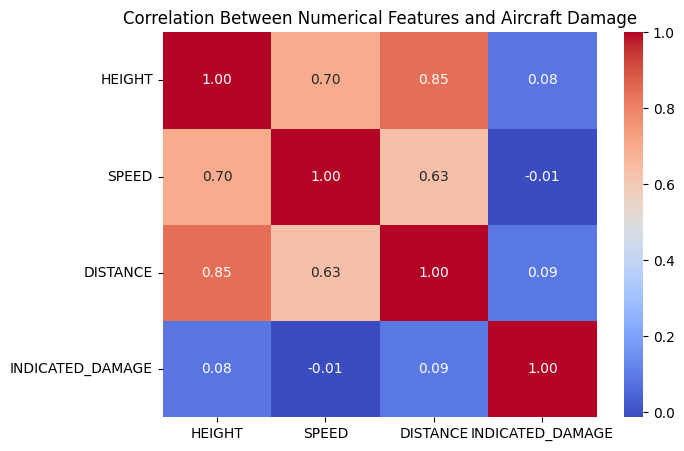

In [72]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numerical Features and Aircraft Damage")
plt.show()

With target variable:

In [73]:
correlations = df[["HEIGHT", "SPEED", "DISTANCE", "INDICATED_DAMAGE"]].corr()["INDICATED_DAMAGE"].drop("INDICATED_DAMAGE")
correlations.sort_values(ascending=False)

,INDICATED_DAMAGE
DISTANCE,0.093599
HEIGHT,0.084446
SPEED,-0.012944


In [74]:
correlations = df[["HEIGHT", "SPEED", "DISTANCE", "INDICATED_DAMAGE"]].corr()["INDICATED_DAMAGE"].drop("INDICATED_DAMAGE").sort_values()

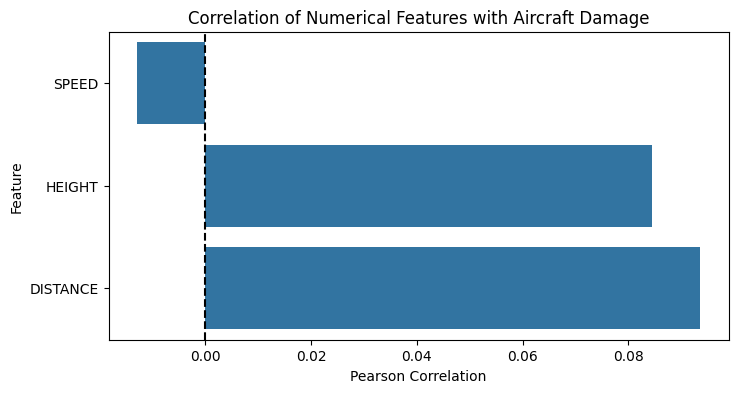

In [75]:
plt.figure(figsize=(8, 4))
sns.barplot(x=correlations.values, y=correlations.index)
plt.title("Correlation of Numerical Features with Aircraft Damage")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.axvline(0, color="black", linestyle="--")
plt.show()

**Finding:** Distance from the airport (0.094) and aircraft height (0.084) show weak positive correlations with reported damage, while aircraft speed (-0.013) shows almost no linear correlation.

These results suggest that none of the three numerical variables has a strong linear relationship with damage on its own. However, they may still contribute to classification models through nonlinear relationships or interactions with other features. Missing values also limit the correlation analysis.

### Feature Engineering

Aircraft height may have a nonlinear relationship with wildlife-strike damage. To explore this possibility, height is grouped into four categories: Ground, Low, Medium, and High. Missing heights are retained as Unknown.

The original numerical height feature will be preserved so that the engineered feature can be evaluated without losing its continuous information.

In [76]:
df["HEIGHT_CATEGORY"] = pd.cut(df["HEIGHT"], bins=[-1, 0, 500, 3000, np.inf], labels=["Ground", "Low", "Medium", "High"])
df["HEIGHT_CATEGORY"] = df["HEIGHT_CATEGORY"].cat.add_categories("Unknown").fillna("Unknown")

In [77]:
height_damage = df.groupby("HEIGHT_CATEGORY", observed=True)["INDICATED_DAMAGE"].mean().mul(100)

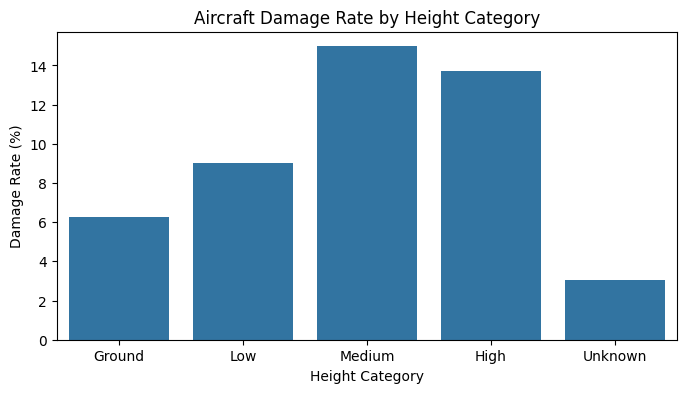

In [78]:
plt.figure(figsize=(8, 4))
sns.barplot(x=height_damage.index, y=height_damage.values)
plt.title("Aircraft Damage Rate by Height Category")
plt.xlabel("Height Category")
plt.ylabel("Damage Rate (%)")
plt.show()

In [79]:
df.groupby("HEIGHT_CATEGORY", observed=True)["INDICATED_DAMAGE"].agg(["count", "sum", "mean"])

,count,sum,mean
HEIGHT_CATEGORY,,,
Ground,77282,4838,0.062602
Low,49254,4432,0.089983
Medium,36871,5520,0.149711
High,14887,2038,0.136898
Unknown,182886,5539,0.030287


## Model Training and Evaluation

### Experiment 1: Comparing Baseline Classification Models

The first experiment compares several classification algorithms to predict whether a reported wildlife strike resulted in aircraft damage.

The models include a majority-class baseline, Logistic Regression, Decision Tree, and Random Forest.

Because only 6.19% of incidents report damage, accuracy alone may be misleading. Model performance will also be compared using precision, recall, F1-score, ROC-AUC, and average precision.

A validation set will be created from the training data for model comparison, while the original test set will remain reserved for final evaluation.

In [80]:
from sklearn.model_selection import train_test_split

In [81]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [82]:
print("Model training:", X_fit.shape)
print("Validation:", X_val.shape)

Model training: (231155, 14)
Validation: (57789, 14)


In [83]:
from sklearn.base import clone

In [84]:
validation_preprocessor = clone(preprocessor)

X_fit_prepared = validation_preprocessor.fit_transform(X_fit)
X_val_prepared = validation_preprocessor.transform(X_val)

In [85]:
print("Training features:", X_fit_prepared.shape)
print("Validation features:", X_val_prepared.shape)

Training features: (231155, 81)
Validation features: (57789, 81)


classifiers chosen:

In [86]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,classification_report, confusion_matrix, ConfusionMatrixDisplay

### Logistic Regression

Logistic Regression is used as the first classification model to predict whether a wildlife strike resulted in aircraft damage.

The model is trained using the prepared training data and evaluated on the validation set. Because the target variable is imbalanced, both accuracy and classification metrics for the damage class will be examined.

In [87]:
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_fit_prepared, y_fit)

LogisticRegression(max_iter=1000)

In [88]:
lr_pred = lr_model.predict(X_val_prepared)
lr_prob = lr_model.predict_proba(X_val_prepared)[:, 1]

In [89]:
print("Accuracy:", round(accuracy_score(y_val, lr_pred), 4))
print("Precision:", round(precision_score(y_val, lr_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, lr_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_val, lr_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, lr_prob), 4))
print("Average Precision:", round(average_precision_score(y_val, lr_prob), 4))

print("\nClassification Report:")
print(classification_report(y_val, lr_pred, target_names=["No Damage", "Damage"], zero_division=0))

Accuracy: 0.9436
Precision: 0.6492
Recall: 0.1939
F1 Score: 0.2986
ROC-AUC: 0.8766
Average Precision: 0.4117

Classification Report:
              precision    recall  f1-score   support

   No Damage       0.95      0.99      0.97     54210
      Damage       0.65      0.19      0.30      3579

    accuracy                           0.94     57789
   macro avg       0.80      0.59      0.63     57789
weighted avg       0.93      0.94      0.93     57789



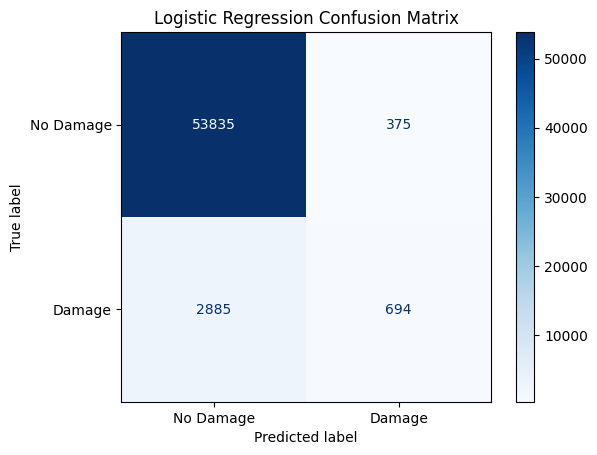

In [90]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_val, lr_pred, display_labels=["No Damage", "Damage"], cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

### Decision Tree

A Decision Tree classifier is trained to capture nonlinear relationships between wildlife strike characteristics and aircraft damage. Its predictions will be compared with Logistic Regression using the same validation data.

In [91]:
dt_model = DecisionTreeClassifier(max_depth=10, random_state=42)
dt_model.fit(X_fit_prepared, y_fit)

DecisionTreeClassifier(max_depth=10, random_state=42)

In [92]:
dt_pred = dt_model.predict(X_val_prepared)
dt_prob = dt_model.predict_proba(X_val_prepared)[:, 1]

In [93]:
print("Accuracy:", round(accuracy_score(y_val, dt_pred), 4))
print("Precision:", round(precision_score(y_val, dt_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, dt_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_val, dt_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, dt_prob), 4))
print("Average Precision:", round(average_precision_score(y_val, dt_prob), 4))

print("\nClassification Report:")
print(classification_report(y_val, dt_pred, target_names=["No Damage", "Damage"], zero_division=0))

Accuracy: 0.9442
Precision: 0.6315
Recall: 0.2395
F1 Score: 0.3472
ROC-AUC: 0.8683
Average Precision: 0.3881

Classification Report:
              precision    recall  f1-score   support

   No Damage       0.95      0.99      0.97     54210
      Damage       0.63      0.24      0.35      3579

    accuracy                           0.94     57789
   macro avg       0.79      0.62      0.66     57789
weighted avg       0.93      0.94      0.93     57789



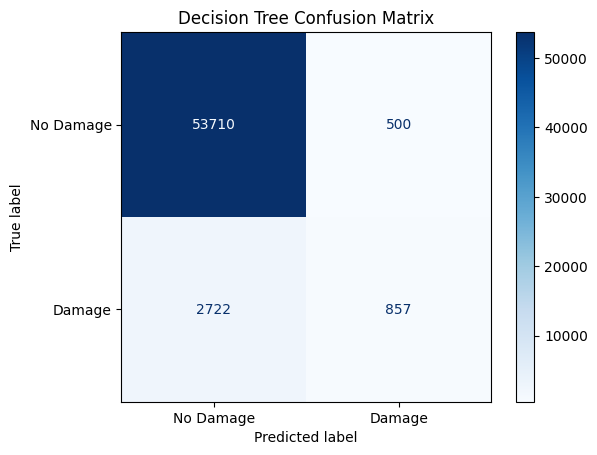

In [94]:
ConfusionMatrixDisplay.from_predictions(y_val, dt_pred, display_labels=["No Damage", "Damage"], cmap="Blues")
plt.title("Decision Tree Confusion Matrix")
plt.show()

### Random Forest

Random Forest combines multiple decision trees to make predictions. It is used to investigate whether an ensemble model performs better than the individual Decision Tree and Logistic Regression models.

In [95]:
rf_model = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
rf_model.fit(X_fit_prepared, y_fit)

RandomForestClassifier(max_depth=15, n_jobs=-1, random_state=42)

In [96]:
rf_pred = rf_model.predict(X_val_prepared)
rf_prob = rf_model.predict_proba(X_val_prepared)[:, 1]

In [97]:
print("Accuracy:", round(accuracy_score(y_val, rf_pred), 4))
print("Precision:", round(precision_score(y_val, rf_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, rf_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_val, rf_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, rf_prob), 4))
print("Average Precision:", round(average_precision_score(y_val, rf_prob), 4))
print("\nClassification Report:")
print(classification_report(y_val, rf_pred, target_names=["No Damage", "Damage"], zero_division=0))

Accuracy: 0.9455
Precision: 0.7144
Recall: 0.2006
F1 Score: 0.3133
ROC-AUC: 0.8878
Average Precision: 0.4585

Classification Report:
              precision    recall  f1-score   support

   No Damage       0.95      0.99      0.97     54210
      Damage       0.71      0.20      0.31      3579

    accuracy                           0.95     57789
   macro avg       0.83      0.60      0.64     57789
weighted avg       0.94      0.95      0.93     57789



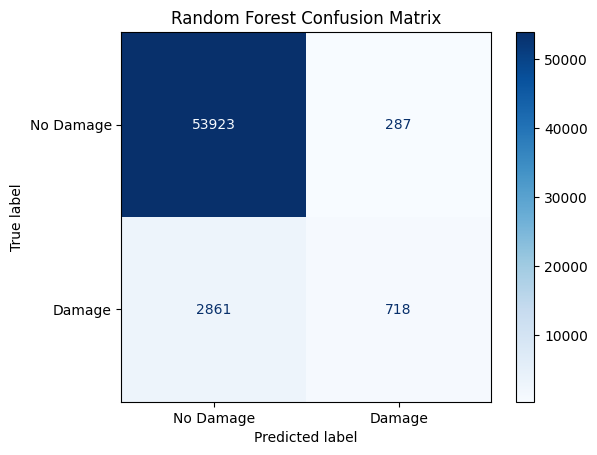

In [98]:
ConfusionMatrixDisplay.from_predictions(y_val, rf_pred, display_labels=["No Damage", "Damage"], cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.show()

### Baseline Model Comparison

The three classification models are compared to determine which performs best at predicting aircraft damage.

Although all three models achieve over 94% accuracy, their recall for damaging incidents is relatively low. This suggests that the models are better at identifying non-damaging incidents than detecting aircraft damage.

Random Forest achieves the highest ROC-AUC and average precision, while Decision Tree achieves the highest recall and F1-score for the damage class. Further experiments will examine whether class weighting can improve damage detection.

In [99]:
# compare models
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Accuracy": [accuracy_score(y_val, lr_pred), accuracy_score(y_val, dt_pred), accuracy_score(y_val, rf_pred)],
    "Precision": [precision_score(y_val, lr_pred), precision_score(y_val, dt_pred), precision_score(y_val, rf_pred)],
    "Recall": [recall_score(y_val, lr_pred), recall_score(y_val, dt_pred), recall_score(y_val, rf_pred)],
    "F1": [f1_score(y_val, lr_pred), f1_score(y_val, dt_pred), f1_score(y_val, rf_pred)],
    "ROC-AUC": [roc_auc_score(y_val, lr_prob), roc_auc_score(y_val, dt_prob), roc_auc_score(y_val, rf_prob)],
    "Avg Precision": [average_precision_score(y_val, lr_prob), average_precision_score(y_val, dt_prob), average_precision_score(y_val, rf_prob)]
})

comparison.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Avg Precision
0,Logistic Regression,0.9436,0.6492,0.1939,0.2986,0.8766,0.4117
1,Decision Tree,0.9442,0.6315,0.2395,0.3472,0.8683,0.3881
2,Random Forest,0.9455,0.7144,0.2006,0.3133,0.8878,0.4585


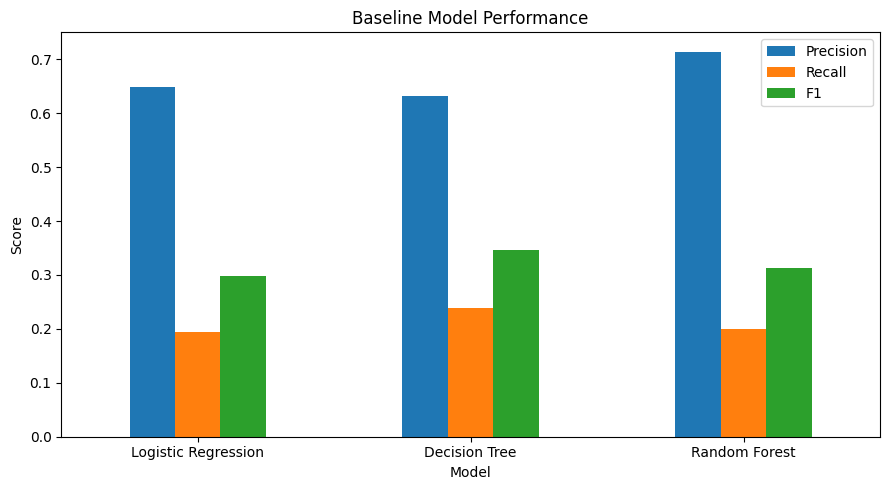

In [100]:
fig, ax = plt.subplots(figsize=(9, 5))
comparison.set_index("Model")[["Precision", "Recall", "F1"]].plot(kind="bar", ax=ax)

ax.set_title("Baseline Model Performance")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_xticklabels(comparison["Model"], rotation=0)
ax.legend()

plt.tight_layout()
plt.show()

### ROC and Precision-Recall Curves

ROC curves are used to compare how well the models distinguish damaging from non-damaging incidents across different classification thresholds.

Precision-recall curves are also examined because damaging incidents represent a small proportion of the dataset. These curves help evaluate the tradeoff between detecting damage and limiting false-positive predictions.

In [101]:
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import PrecisionRecallDisplay

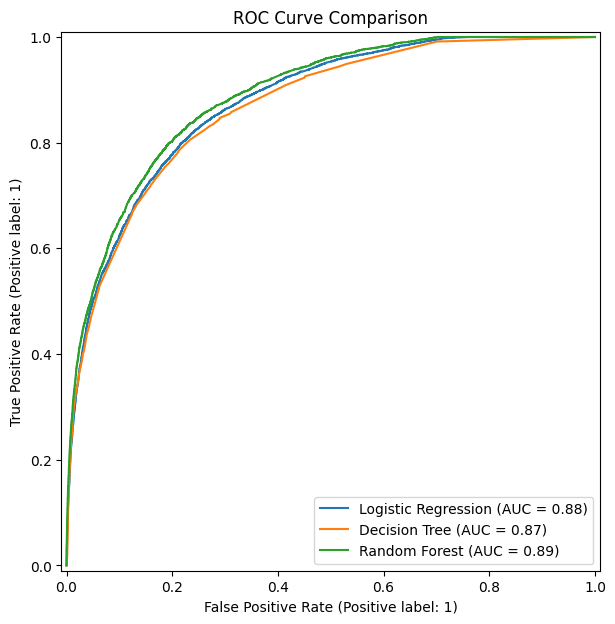

In [102]:
fig, ax = plt.subplots(figsize=(10, 7))

RocCurveDisplay.from_predictions(y_val, lr_prob, name="Logistic Regression", ax=ax)
RocCurveDisplay.from_predictions(y_val, dt_prob, name="Decision Tree", ax=ax)
RocCurveDisplay.from_predictions(y_val, rf_prob, name="Random Forest", ax=ax)

plt.title("ROC Curve Comparison")
plt.show()

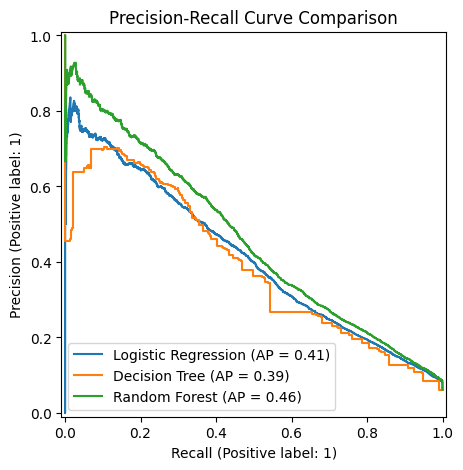

In [103]:
fig, ax = plt.subplots(figsize=(8, 5))
PrecisionRecallDisplay.from_predictions(y_val, lr_prob, name="Logistic Regression", ax=ax)
PrecisionRecallDisplay.from_predictions(y_val, dt_prob, name="Decision Tree", ax=ax)
PrecisionRecallDisplay.from_predictions(y_val, rf_prob, name="Random Forest", ax=ax)

plt.title("Precision-Recall Curve Comparison")
plt.show()

Class imbalance experiment

In [104]:
weighted_lr = LogisticRegression(max_iter=1000, class_weight="balanced")
weighted_lr.fit(X_fit_prepared, y_fit)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [105]:
weighted_lr_pred = weighted_lr.predict(X_val_prepared)
weighted_lr_prob = weighted_lr.predict_proba(X_val_prepared)[:, 1]

### Weighted Logistic Regression Evaluation
Class weighting may recover more damaging incidents, but it can also increase false alarms. Compare its scores against the original model rather than relying on accuracy alone.

In [106]:
print("Weighted Logistic Regression")
print("Accuracy:", round(accuracy_score(y_val, weighted_lr_pred), 4))
print("Precision:", round(precision_score(y_val, weighted_lr_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, weighted_lr_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_val, weighted_lr_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, weighted_lr_prob), 4))
print("Average Precision:", round(average_precision_score(y_val, weighted_lr_prob), 4))
print("\nClassification Report:")
print(classification_report(y_val, weighted_lr_pred, target_names=["No Damage", "Damage"], zero_division=0))

Weighted Logistic Regression
Accuracy: 0.793
Precision: 0.2011
Recall: 0.7879
F1 Score: 0.3204
ROC-AUC: 0.8775
Average Precision: 0.4038

Classification Report:
              precision    recall  f1-score   support

   No Damage       0.98      0.79      0.88     54210
      Damage       0.20      0.79      0.32      3579

    accuracy                           0.79     57789
   macro avg       0.59      0.79      0.60     57789
weighted avg       0.93      0.79      0.84     57789



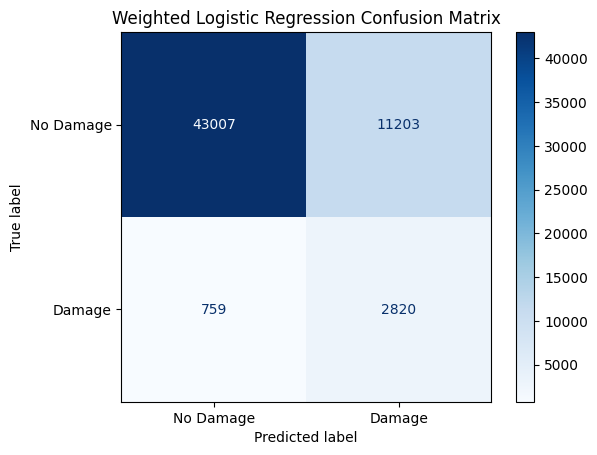

In [107]:
ConfusionMatrixDisplay.from_predictions(y_val, weighted_lr_pred, display_labels=["No Damage", "Damage"], cmap="Blues")
plt.title("Weighted Logistic Regression Confusion Matrix")
plt.show()

### Weighted Decision Tree and Random Forest
These classifiers support class_weight="balanced". We train them independently, following the same `fit()` -> `predict()` -> `classification_report()` sequence used earlier.

In [108]:
weighted_dt = DecisionTreeClassifier(max_depth=10, class_weight="balanced", random_state=42)
weighted_dt.fit(X_fit_prepared, y_fit)
weighted_dt_pred = weighted_dt.predict(X_val_prepared)
weighted_dt_prob = weighted_dt.predict_proba(X_val_prepared)[:, 1]

Weighted Decision Tree
              precision    recall  f1-score   support

   No Damage       0.98      0.79      0.88     54210
      Damage       0.20      0.79      0.32      3579

    accuracy                           0.79     57789
   macro avg       0.59      0.79      0.60     57789
weighted avg       0.93      0.79      0.84     57789

ROC-AUC: 0.8696
Average Precision: 0.3979


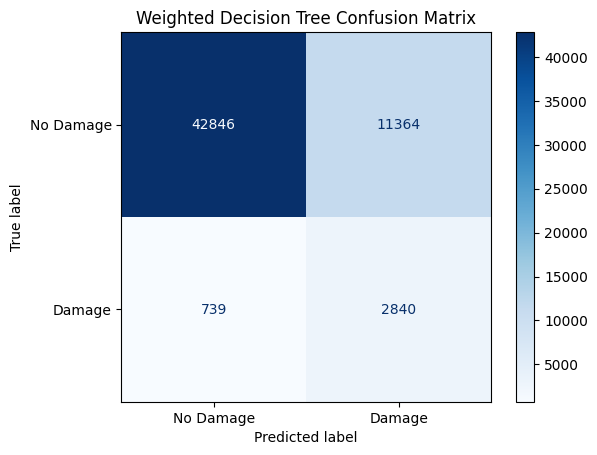

In [109]:
print("Weighted Decision Tree")
print(classification_report(y_val, weighted_dt_pred, target_names=["No Damage", "Damage"], zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_val, weighted_dt_prob), 4))
print("Average Precision:", round(average_precision_score(y_val, weighted_dt_prob), 4))
ConfusionMatrixDisplay.from_predictions(y_val, weighted_dt_pred, display_labels=["No Damage", "Damage"], cmap="Blues")
plt.title("Weighted Decision Tree Confusion Matrix")
plt.show()

In [110]:
weighted_rf = RandomForestClassifier(n_estimators=100, max_depth=15, class_weight="balanced", random_state=42, n_jobs=-1)
weighted_rf.fit(X_fit_prepared, y_fit)
weighted_rf_pred = weighted_rf.predict(X_val_prepared)
weighted_rf_prob = weighted_rf.predict_proba(X_val_prepared)[:, 1]

Weighted Random Forest
              precision    recall  f1-score   support

   No Damage       0.98      0.84      0.91     54210
      Damage       0.24      0.73      0.36      3579

    accuracy                           0.84     57789
   macro avg       0.61      0.79      0.63     57789
weighted avg       0.93      0.84      0.87     57789

ROC-AUC: 0.8817
Average Precision: 0.4347


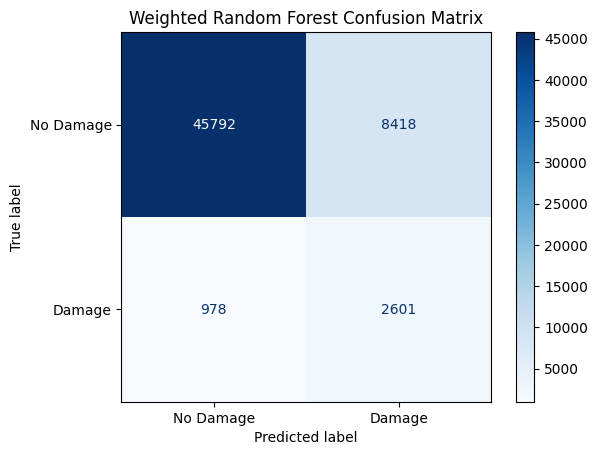

In [111]:
print("Weighted Random Forest")
print(classification_report(y_val, weighted_rf_pred, target_names=["No Damage", "Damage"], zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_val, weighted_rf_prob), 4))
print("Average Precision:", round(average_precision_score(y_val, weighted_rf_prob), 4))
ConfusionMatrixDisplay.from_predictions(y_val, weighted_rf_pred, display_labels=["No Damage", "Damage"], cmap="Blues")
plt.title("Weighted Random Forest Confusion Matrix")
plt.show()

### Standard vs. Weighted Models
We compare each model's default decision threshold (0.50). Average precision measures performance across thresholds, while F1 and recall describe the labels predicted at 0.50. The balanced class weights are a modeling choice, not a guarantee of improved results.

In [112]:
weighted_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Weighted Logistic Regression", "Decision Tree", "Weighted Decision Tree", "Random Forest", "Weighted Random Forest"],
    "Accuracy": [accuracy_score(y_val, p) for p in [lr_pred, weighted_lr_pred, dt_pred, weighted_dt_pred, rf_pred, weighted_rf_pred]],
    "Precision": [precision_score(y_val, p, zero_division=0) for p in [lr_pred, weighted_lr_pred, dt_pred, weighted_dt_pred, rf_pred, weighted_rf_pred]],
    "Recall": [recall_score(y_val, p, zero_division=0) for p in [lr_pred, weighted_lr_pred, dt_pred, weighted_dt_pred, rf_pred, weighted_rf_pred]],
    "F1": [f1_score(y_val, p, zero_division=0) for p in [lr_pred, weighted_lr_pred, dt_pred, weighted_dt_pred, rf_pred, weighted_rf_pred]],
    "ROC-AUC": [roc_auc_score(y_val, p) for p in [lr_prob, weighted_lr_prob, dt_prob, weighted_dt_prob, rf_prob, weighted_rf_prob]],
    "Avg Precision": [average_precision_score(y_val, p) for p in [lr_prob, weighted_lr_prob, dt_prob, weighted_dt_prob, rf_prob, weighted_rf_prob]]
})
weighted_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Avg Precision
0,Logistic Regression,0.9436,0.6492,0.1939,0.2986,0.8766,0.4117
1,Weighted Logistic Regression,0.7930,0.2011,0.7879,0.3204,0.8775,0.4038
2,Decision Tree,0.9442,0.6315,0.2395,0.3472,0.8683,0.3881
3,Weighted Decision Tree,0.7906,0.1999,0.7935,0.3194,0.8696,0.3979
4,Random Forest,0.9455,0.7144,0.2006,0.3133,0.8878,0.4585
5,Weighted Random Forest,0.8374,0.2360,0.7267,0.3564,0.8817,0.4347


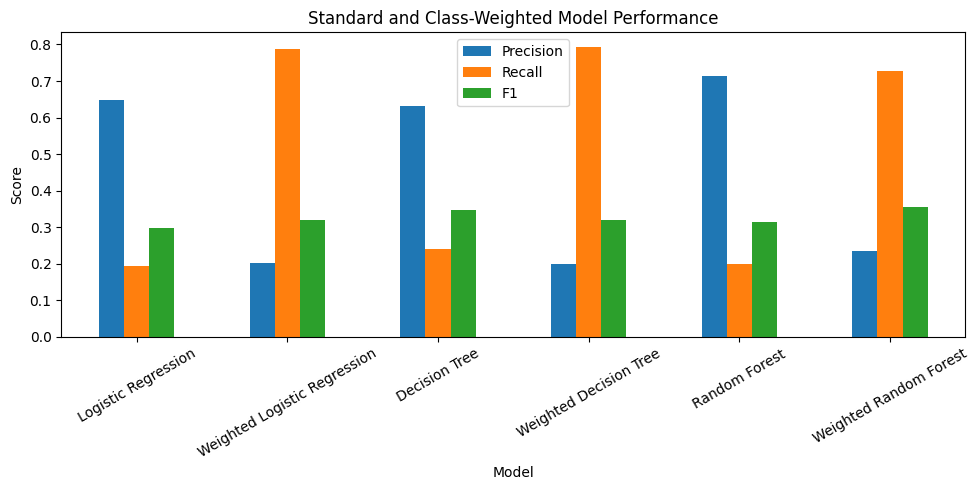

In [113]:
fig, ax = plt.subplots(figsize=(10, 5))
weighted_comparison.set_index("Model")[["Precision", "Recall", "F1"]].plot(kind="bar", ax=ax)
ax.set_title("Standard and Class-Weighted Model Performance")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## Selecting and Tuning a Model
We shortlist the model with the highest validation average precision, since aircraft damage is rare. We then apply a small three-fold stratified GridSearchCV to the training portion only. Importantly, preprocessing is inside the pipeline, so each cross-validation fold learns its imputation, scaling, and encoding from its own training rows. The test set is still untouched.

This is a focused search, not an exhaustive hyperparameter study. It follows the class pattern of fitting a model, comparing metrics, and tuning only where useful.

In [114]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

In [115]:
best_initial_name = weighted_comparison.sort_values("Avg Precision", ascending=False).iloc[0]["Model"]
print("Best initial validation average precision:", best_initial_name)

Best initial validation average precision: Random Forest


In [116]:
if best_initial_name == "Logistic Regression":
    candidate_model = LogisticRegression(max_iter=1000)
elif best_initial_name == "Weighted Logistic Regression":
    candidate_model = LogisticRegression(max_iter=1000, class_weight="balanced")
elif best_initial_name == "Decision Tree":
    candidate_model = DecisionTreeClassifier(random_state=42)
elif best_initial_name == "Weighted Decision Tree":
    candidate_model = DecisionTreeClassifier(class_weight="balanced", random_state=42)
elif best_initial_name == "Random Forest":
    candidate_model = RandomForestClassifier(n_estimators=80, random_state=42, n_jobs=-1)
else:
    candidate_model = RandomForestClassifier(n_estimators=80, class_weight="balanced", random_state=42, n_jobs=-1)

model_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", candidate_model)
])

In [117]:
if "Logistic Regression" in best_initial_name:
    parameters = {"model__C": [0.1, 1, 10]}
elif "Decision Tree" in best_initial_name:
    parameters = {"model__max_depth": [6, 10, 15], "model__min_samples_leaf": [5, 20]}
else:
    parameters = {"model__max_depth": [12, 18], "model__min_samples_leaf": [2, 10]}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
search = GridSearchCV(model_pipeline, parameters, cv=cv, scoring="average_precision", n_jobs=1, refit=True)
search.fit(X_fit, y_fit)

print("Best CV average precision:", round(search.best_score_, 4))
print("Best parameters:", search.best_params_)

Best CV average precision: 0.4526
Best parameters: {'model__max_depth': 18, 'model__min_samples_leaf': 2}


## Evaluate tuned model on validation data
The tuning score comes from cross-validation within the training portion. We evaluate the tuned model on the separate validation set to decide whether tuning was worthwhile. We will not choose a model based on the final test outcomes.

In [118]:
tuned_pipeline = search.best_estimator_
tuned_val_prob = tuned_pipeline.predict_proba(X_val)[:, 1]
tuned_val_pred = tuned_pipeline.predict(X_val)

In [119]:
initial_ap = weighted_comparison.set_index("Model").loc[best_initial_name, "Avg Precision"]
tuned_ap = average_precision_score(y_val, tuned_val_prob)
print("Initial validation average precision:", round(initial_ap, 4))
print("Tuned validation average precision:", round(tuned_ap, 4))
print("Tuned validation F1:", round(f1_score(y_val, tuned_val_pred, zero_division=0), 4))
print("Tuned validation ROC-AUC:", round(roc_auc_score(y_val, tuned_val_prob), 4))

Initial validation average precision: 0.4585
Tuned validation average precision: 0.4585
Tuned validation F1: 0.3345
Tuned validation ROC-AUC: 0.8884


## Does the Engineered Height Category Help?
The EDA showed differences in damage rates by altitude group. We compare the tuned model using the original 14 features against an otherwise identical model that includes the fixed `HEIGHT_CATEGORY` bins. The continuous `HEIGHT` measurement remains included in both versions. This comparison uses validation data only.

In [120]:
def add_height_category(data):
    data = data.copy()
    data["HEIGHT_CATEGORY"] = pd.cut(data["HEIGHT"], bins=[-1, 0, 500, 3000, np.inf], labels=["Ground", "Low", "Medium", "High"]).astype("string").fillna("Unknown").astype(str)
    return data

In [121]:
X_fit_height = add_height_category(X_fit)
X_val_height = add_height_category(X_val)

In [122]:
height_preprocessor = ColumnTransformer([
    ("numeric", clone(numeric_preprocessor), numeric_cols),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols + ["HEIGHT_CATEGORY"])
])
height_pipeline = Pipeline([
    ("preprocessor", height_preprocessor),
    ("model", clone(tuned_pipeline.named_steps["model"]))
])
height_pipeline.fit(X_fit_height, y_fit)
height_val_prob = height_pipeline.predict_proba(X_val_height)[:, 1]
height_ap = average_precision_score(y_val, height_val_prob)

In [123]:
print("Original-feature validation AP:", round(tuned_ap, 4))
print("With HEIGHT_CATEGORY validation AP:", round(height_ap, 4))
print("Difference:", round(height_ap - tuned_ap, 4))

Original-feature validation AP: 0.4585
With HEIGHT_CATEGORY validation AP: 0.4563
Difference: -0.0022


## Does reporting completeness influence predictions?
About half of records have missing height and many lack speed data. Our numeric imputer currently adds explicit missingness indicators. As a focused sensitivity analysis, we remove the numeric missingness indicators only, while keeping numeric imputation and categorical Unknown levels the same. This helps test dependence on missingness signals; it does not eliminate every form of reporting bias.

In [124]:
no_indicator_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_cols),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])
no_indicator_pipeline = Pipeline([
    ("preprocessor", no_indicator_preprocessor),
    ("model", clone(tuned_pipeline.named_steps["model"]))
])

In [125]:
no_indicator_pipeline.fit(X_fit, y_fit)
no_indicator_prob = no_indicator_pipeline.predict_proba(X_val)[:, 1]
print("Original-feature AP:", round(tuned_ap, 4))
print("Without numeric missingness indicators AP:", round(average_precision_score(y_val, no_indicator_prob), 4))
print("Interpretation: A change measures reliance on numeric missingness patterns, not causation.")

Original-feature AP: 0.4585
Without numeric missingness indicators AP: 0.4558
Interpretation: A change measures reliance on numeric missingness patterns, not causation.


## Select the Final Model and Classification Threshold
We compare tuned original features and tuned model + height category on the validation set. To avoid favoring extra complexity for negligible changes, the engineered feature is retained only if validation average precision increases by at least 0.005 (a simple predeclared practical margin). We choose a classification threshold that maximizes validation F1; this makes the precision–recall tradeoff explicit. The final test set is not used for either decision.

In [126]:
from sklearn.metrics import precision_recall_curve

In [127]:
use_height = height_ap >= tuned_ap + 0.005
final_model_template = height_pipeline if use_height else tuned_pipeline
final_features = "Original + HEIGHT_CATEGORY" if use_height else "Original 14 features"
selected_val_prob = height_val_prob if use_height else tuned_val_prob

In [128]:
precision_values, recall_values, thresholds = precision_recall_curve(y_val, selected_val_prob)
f1_values = 2 * precision_values[:-1] * recall_values[:-1] / (precision_values[:-1] + recall_values[:-1] + 1e-12)
best_threshold = float(thresholds[np.argmax(f1_values)])
selected_val_pred = (selected_val_prob >= best_threshold).astype(int)

In [129]:
print("Selected model family:", best_initial_name)
print("Selected features:", final_features)
print("Validation-selected threshold:", round(best_threshold, 4))
print("Validation precision:", round(precision_score(y_val, selected_val_pred, zero_division=0), 4))
print("Validation recall:", round(recall_score(y_val, selected_val_pred, zero_division=0), 4))
print("Validation F1:", round(f1_score(y_val, selected_val_pred, zero_division=0), 4))
print("Validation average precision:", round(average_precision_score(y_val, selected_val_prob), 4))

Selected model family: Random Forest
Selected features: Original 14 features
Validation-selected threshold: 0.2478
Validation precision: 0.4859
Validation recall: 0.4512
Validation F1: 0.4679
Validation average precision: 0.4585


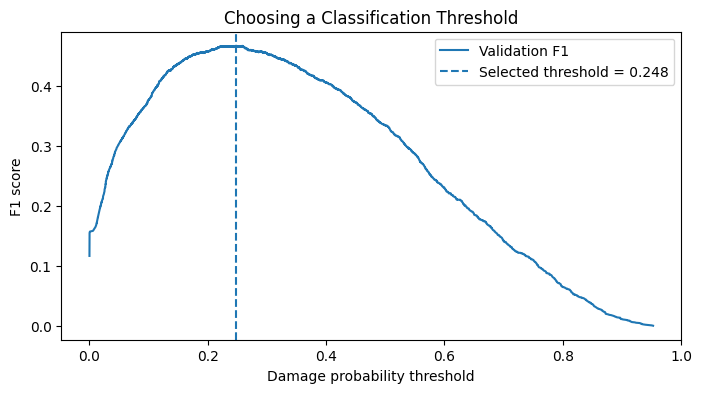

In [130]:
plt.figure(figsize=(8, 4))
plt.plot(thresholds, f1_values, label="Validation F1")
plt.axvline(best_threshold, linestyle="--", label=f"Selected threshold = {best_threshold:.3f}")
plt.xlabel("Damage probability threshold")
plt.ylabel("F1 score")
plt.title("Choosing a Classification Threshold")
plt.legend()
plt.show()

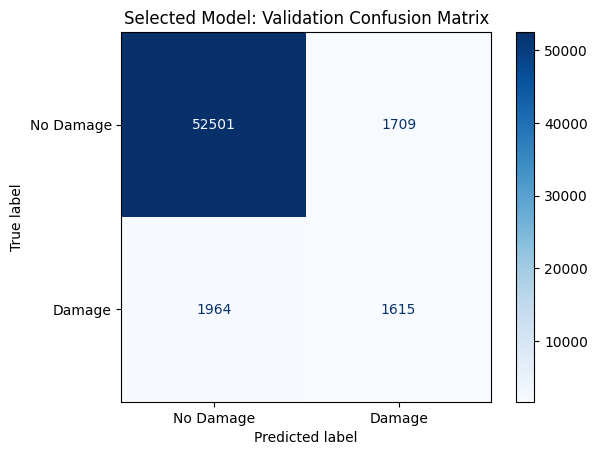

In [131]:
ConfusionMatrixDisplay.from_predictions(y_val, selected_val_pred, display_labels=["No Damage", "Damage"], cmap="Blues")
plt.title("Selected Model: Validation Confusion Matrix")
plt.show()

## Final Test Evaluation Unseen Incidents
We now refit the selected preprocessing and model configuration on all of X_train, then make predictions on X_test once. The validation-selected threshold is fixed. The test results are reported as final estimates of generalization and must not be used to retune the model.

In [132]:
final_model = clone(final_model_template)
X_train_final = add_height_category(X_train) if use_height else X_train
X_test_final = add_height_category(X_test) if use_height else X_test

In [133]:
final_model.fit(X_train_final, y_train)
test_prob = final_model.predict_proba(X_test_final)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

In [134]:
print("FINAL TEST RESULTS:", best_initial_name, "|", final_features)
print("Threshold:", round(best_threshold, 4))
print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Precision:", round(precision_score(y_test, test_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, test_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))
print("Average Precision:", round(average_precision_score(y_test, test_prob), 4))
print("\nClassification Report:")
print(classification_report(y_test, test_pred, target_names=["No Damage", "Damage"], zero_division=0))

FINAL TEST RESULTS: Random Forest | Original 14 features
Threshold: 0.2478
Accuracy: 0.9339
Precision: 0.4644
Recall: 0.4368
F1 Score: 0.4502
ROC-AUC: 0.8849
Average Precision: 0.4457

Classification Report:
              precision    recall  f1-score   support

   No Damage       0.96      0.97      0.96     67763
      Damage       0.46      0.44      0.45      4473

    accuracy                           0.93     72236
   macro avg       0.71      0.70      0.71     72236
weighted avg       0.93      0.93      0.93     72236



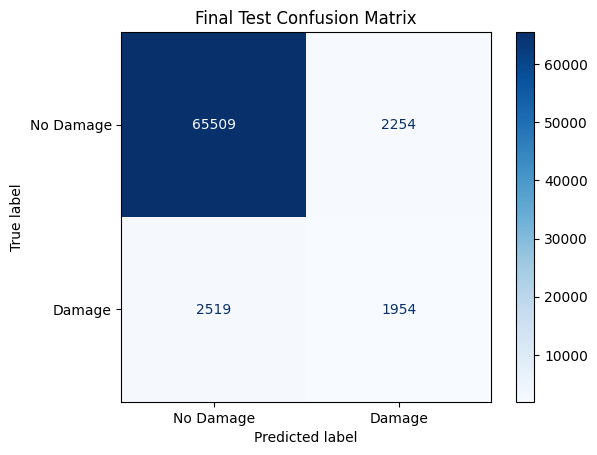

In [135]:
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["No Damage", "Damage"], cmap="Blues")
plt.title("Final Test Confusion Matrix")
plt.show()

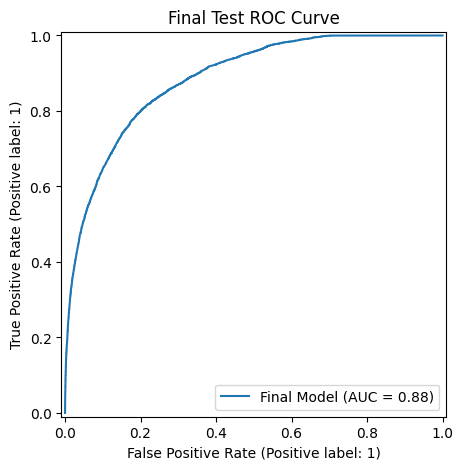

In [136]:
fig, ax = plt.subplots(figsize=(8, 5))
RocCurveDisplay.from_predictions(y_test, test_prob, name="Final Model", ax=ax)
ax.set_title("Final Test ROC Curve")
plt.show()

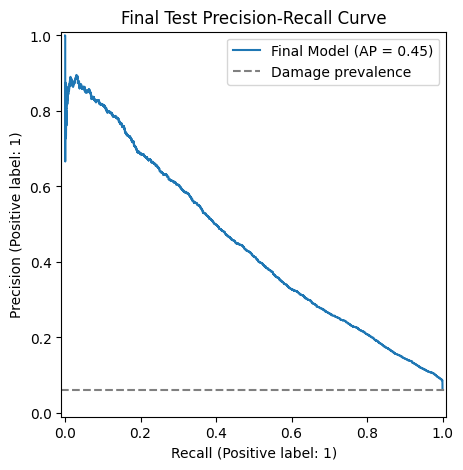

In [137]:
fig, ax = plt.subplots(figsize=(8, 5))
PrecisionRecallDisplay.from_predictions(y_test, test_prob, name="Final Model", ax=ax)
ax.axhline(y_test.mean(), linestyle="--", color="gray", label="Damage prevalence")
ax.set_title("Final Test Precision-Recall Curve")
ax.legend()
plt.show()

## Interpreting Model Predictions
Feature importance helps us identify associations used by the model, not causes of aircraft damage. For tree models, we examine impurity-based importance; for Logistic Regression, we examine the magnitude of standardized-feature coefficients. Because some source features are one-hot encoded, their expanded column names will appear separately.

In [138]:
final_feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()
final_estimator = final_model.named_steps["model"]

if hasattr(final_estimator, "feature_importances_"):
    importance_values = final_estimator.feature_importances_
    importance_label = "Tree Feature Importance"
else:
    importance_values = np.abs(final_estimator.coef_[0])
    importance_label = "Absolute Logistic Regression Coefficient"

feature_importance = pd.Series(importance_values, index=final_feature_names).sort_values(ascending=False)
print(feature_importance.head(15).round(4))

categorical__SIZE_Large            0.1493
categorical__SIZE_Small            0.0775
numeric__HEIGHT                    0.0656
numeric__SPEED                     0.0476
categorical__SIZE_Medium           0.0438
categorical__TYPE_ENG_A            0.0301
categorical__SIZE_Unknown          0.0218
categorical__AC_MASS_1.0           0.0215
categorical__AC_MASS_4.0           0.0209
numeric__missingindicator_SPEED    0.0202
numeric__DISTANCE                  0.0188
categorical__NUM_ENGS_1.0          0.0178
categorical__TYPE_ENG_D            0.0173
categorical__NUM_ENGS_Unknown      0.0160
categorical__AC_MASS_2.0           0.0155
dtype: float64


## Risk Groups: Which Incidents Receive Higher Predicted Damage Probabilities?
Following the business-focused prediction and risk-ranking ideas in classmate projects, we group the held-out test incidents by predicted damage probability. We then calculate the observed damage rate in each group. This summarizes how effectively the final model ranks already reported wildlife strikes; it is not a forecast of future strike occurrence.

In [139]:
risk_results = pd.DataFrame({"Predicted Probability": test_prob, "Actual Damage": np.asarray(y_test)})
risk_results["Risk Group"] = pd.qcut(risk_results["Predicted Probability"].rank(method="first"), q=5, labels=["Lowest", "Low", "Medium", "High", "Highest"])
risk_summary = risk_results.groupby("Risk Group", observed=True).agg(Incidents=("Actual Damage", "size"), Damage_Rate=("Actual Damage", "mean"), Mean_Predicted_Probability=("Predicted Probability", "mean"))
risk_summary[["Damage_Rate", "Mean_Predicted_Probability"]] = risk_summary[["Damage_Rate", "Mean_Predicted_Probability"]] * 100
print(risk_summary.round(2))

            Incidents  Damage_Rate  Mean_Predicted_Probability
Risk Group                                                    
Lowest          14448         0.00                        0.00
Low             14447         0.62                        0.74
Medium          14447         2.22                        2.24
High            14447         4.74                        5.13
Highest         14447        23.38                       22.96


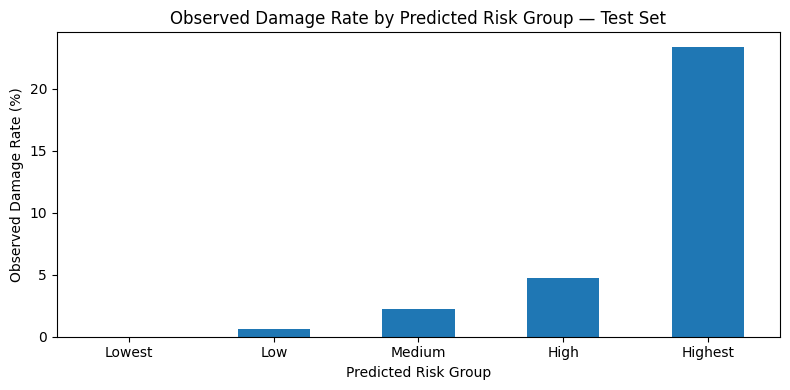

In [140]:
fig, ax = plt.subplots(figsize=(8, 4))
risk_summary["Damage_Rate"].plot(kind="bar", ax=ax)
ax.set_title("Observed Damage Rate by Predicted Risk Group — Test Set")
ax.set_ylabel("Observed Damage Rate (%)")
ax.set_xlabel("Predicted Risk Group")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

In [141]:
prediction_examples = pd.DataFrame({
    "Actual Damage": np.asarray(y_test)[:10],
    "Predicted Probability": np.round(test_prob[:10], 3),
    "Predicted Damage": test_pred[:10]
})
prediction_examples["Actual Damage"] = prediction_examples["Actual Damage"].map({0: "No", 1: "Yes"})
prediction_examples["Predicted Damage"] = prediction_examples["Predicted Damage"].map({0: "No", 1: "Yes"})
prediction_examples

,Actual Damage,Predicted Probability,Predicted Damage
0,No,0.014,No
1,No,0.035,No
2,No,0.080,No
3,No,0.031,No
4,No,0.000,No
5,No,0.085,No
6,No,0.016,No
7,Yes,0.184,No
8,No,0.109,No
9,No,0.000,No


### Data Integrity and Limitations

Repeated incident IDs: INDEX_NR contains eight repeat occurrences despite no identical complete rows. We did not blindly drop rows; matching identifier values may represent data-entry issues or related records. Check whether any identifiers appear in both the training and test partitions.

In [142]:
train_incident_ids = set(df.loc[X_train.index, "INDEX_NR"])
test_incident_ids = set(df.loc[X_test.index, "INDEX_NR"])
shared_incident_ids = train_incident_ids.intersection(test_incident_ids)
print("Number of incident IDs occurring in both train and test:", len(shared_incident_ids))
if shared_incident_ids:
    print("Caution: Shared IDs should be investigated before interpreting the held-out test as fully incident-independent.")

Number of incident IDs occurring in both train and test: 1
Caution: Shared IDs should be investigated before interpreting the held-out test as fully incident-independent.


In [143]:
print("Shared incident IDs:", shared_incident_ids)

shared_records = df[df["INDEX_NR"].isin(shared_incident_ids)]
display(shared_records[[
    "INDEX_NR", "INCIDENT_DATE", "AIRPORT",
    "AIRCRAFT", "PHASE_OF_FLIGHT", "HEIGHT",
    "SPEED", "SIZE", "NUM_STRUCK", "INDICATED_DAMAGE"
]])

Shared incident IDs: {1859904}


,INDEX_NR,INCIDENT_DATE,AIRPORT,AIRCRAFT,PHASE_OF_FLIGHT,HEIGHT,SPEED,SIZE,NUM_STRUCK,INDICATED_DAMAGE
346634,1859904,2026-04-25,PALO ALTO ARPT OF SANTA CLARA COUNTY,UNKNOWN,NaN,NaN,NaN,Medium,1,0
346635,1859904,2026-04-25,PALO ALTO ARPT OF SANTA CLARA COUNTY,UNKNOWN,NaN,NaN,NaN,Medium,1,0


In [144]:
for incident_id in shared_incident_ids:
    records = df[df["INDEX_NR"] == incident_id]
    different_columns = records.columns[records.nunique(dropna=False) > 1]
    print("Incident ID:", incident_id)
    print("Different columns:", different_columns.tolist())

Incident ID: 1859904
Different columns: ['SPECIES']


### Duplicate Incident Investigation

A check for incident identifiers appearing in both the training and test sets identified one overlapping incident (`INDEX_NR = 1859904`).

The two records have identical values for the selected model features and the damage outcome. The only differing field is `SPECIES`, which was not used for model training.

This indicates that records associated with the same reported incident can appear more than once in the database. Although the overlap is very small, it means that the train/test split is not completely independent at the incident level. A future improvement would use incident-based grouping to ensure that records sharing an identifier remain in the same data partition.

# Conclusion

This project explored whether machine learning could predict aircraft damage using reported wildlife-strike characteristics from the FAA Wildlife Strike Database. After exploratory data analysis, preprocessing, and feature selection, three classification models were compared: Logistic Regression, Decision Tree, and Random Forest.

**Random Forest was selected as the final model** based on its validation performance. After hyperparameter tuning and adjusting the classification threshold to 0.2478, the model achieved **93.39% accuracy, 46.44% precision, 43.68% recall, an F1-score of 0.4502, ROC-AUC of 0.8849, and average precision of 0.4457** on the test set.

Although the model achieved high accuracy, it identified fewer than half of the damaging incidents. Since approximately 93.8% of reported strikes resulted in no damage, accuracy alone was not a sufficient measure of performance. Class weighting improved recall but reduced precision, highlighting the tradeoff between identifying damaging incidents and generating false alarms.

Feature importance showed that wildlife size, aircraft height, and speed were among the influential predictors. Additional feature engineering was explored, but including height categories did not improve model performance, so the original feature set was retained.

**From a business and operational perspective, the model's strongest potential application is helping aviation safety teams prioritize the review of reported wildlife strikes.** The risk-group analysis showed that incidents in the highest predicted-risk group had a 23.38% observed damage rate, compared with only 0.62% in the lowest-risk group. This suggests that the model could help identify reports that deserve closer attention, support retrospective safety analysis, and reveal patterns that may inform wildlife hazard management.

However, the model should not replace actual aircraft inspections or operational safety procedures. Missing information and differences in reporting practices may affect its predictions. A duplicate-incident investigation also identified one incident appearing in both training and test data, although the records differed only in species, which was not used for modeling. Future work could improve evaluation by keeping records from the same incident together during data splitting and investigating reporting completeness.

Overall, this project demonstrates how machine learning can identify patterns associated with aircraft damage and distinguish between reported incidents with different levels of predicted damage risk. While the model is not reliable enough to detect every damaging strike, its ability to rank incidents offers a potential way to support more informed analysis and prioritization of aviation safety reports. Because the model uses characteristics recorded during or after an incident, its findings apply to **reported-strike damage prediction rather than predicting future wildlife strikes**.

### Extra: Exploring Model Predictions

To better understand how the final model responds to different wildlife-strike characteristics, one reported incident is selected as an example. The wildlife size is changed while all other recorded features remain constant.

This experiment illustrates how predicted damage probability varies with wildlife size. These predictions are model estimates and should not be interpreted as causal effects.

In [147]:
example = X_test.iloc[[0]].copy()

scenarios = pd.concat([example] * 3, ignore_index=True)
scenarios["SIZE"] = ["Small", "Medium", "Large"]

In [148]:
probabilities = final_model.predict_proba(scenarios)[:, 1] * 100

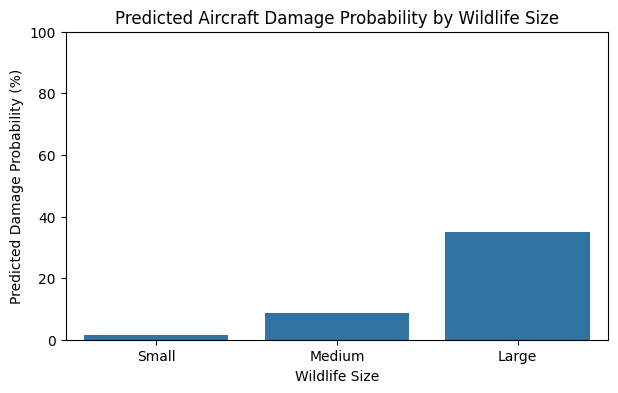

In [149]:
plt.figure(figsize=(7, 4))
sns.barplot(x=scenarios["SIZE"], y=probabilities)
plt.title("Predicted Aircraft Damage Probability by Wildlife Size")
plt.xlabel("Wildlife Size")
plt.ylabel("Predicted Damage Probability (%)")
plt.ylim(0, 100)
plt.show()

### Extra: Exploring Wildlife Strike Scenarios

To demonstrate how the final Random Forest model responds to different reported strike characteristics, several hypothetical scenarios are created by modifying a real test observation.

The visualization compares the predicted probability of aircraft damage across these scenarios. These estimates reflect model behavior rather than actual outcomes or causal effects.

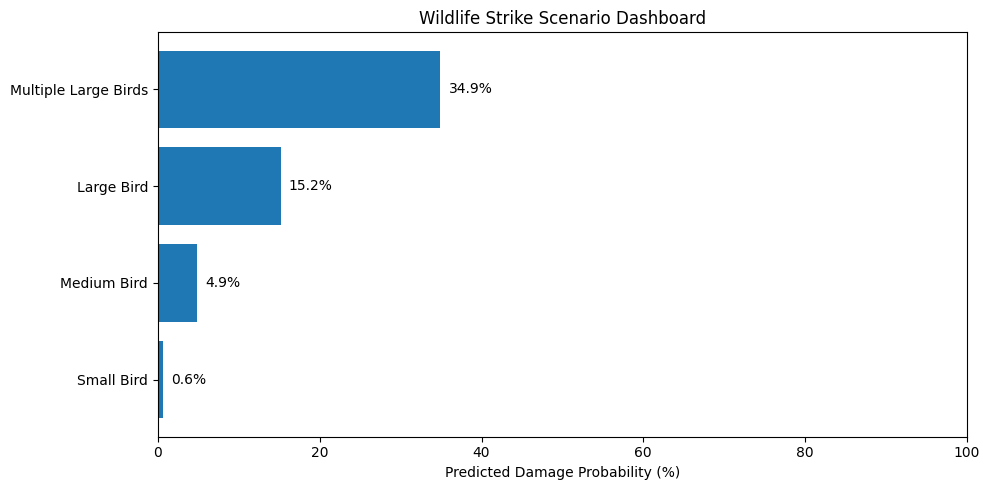

In [150]:
example = X_test.iloc[[0]].copy()

scenarios = pd.concat([example] * 4, ignore_index=True)

scenarios["SIZE"] = ["Small", "Medium", "Large", "Large"]
scenarios["NUM_STRUCK"] = ["1", "1", "1", "2-10"]

scenarios["Scenario"] = [
    "Small Bird",
    "Medium Bird",
    "Large Bird",
    "Multiple Large Birds"
]

probabilities = final_model.predict_proba(
    scenarios.drop(columns="Scenario")
)[:, 1] * 100

plt.figure(figsize=(10, 5))
bars = plt.barh(scenarios["Scenario"], probabilities)

plt.xlabel("Predicted Damage Probability (%)")
plt.title("Wildlife Strike Scenario Dashboard")
plt.xlim(0, 100)

for bar, probability in zip(bars, probabilities):
    plt.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{probability:.1f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

## ✈️ Cleared for Landing

A little Python-drawn send-off to wrap up TECH 68: Machine Learning for Business.

Thanks for flying along! 🐦

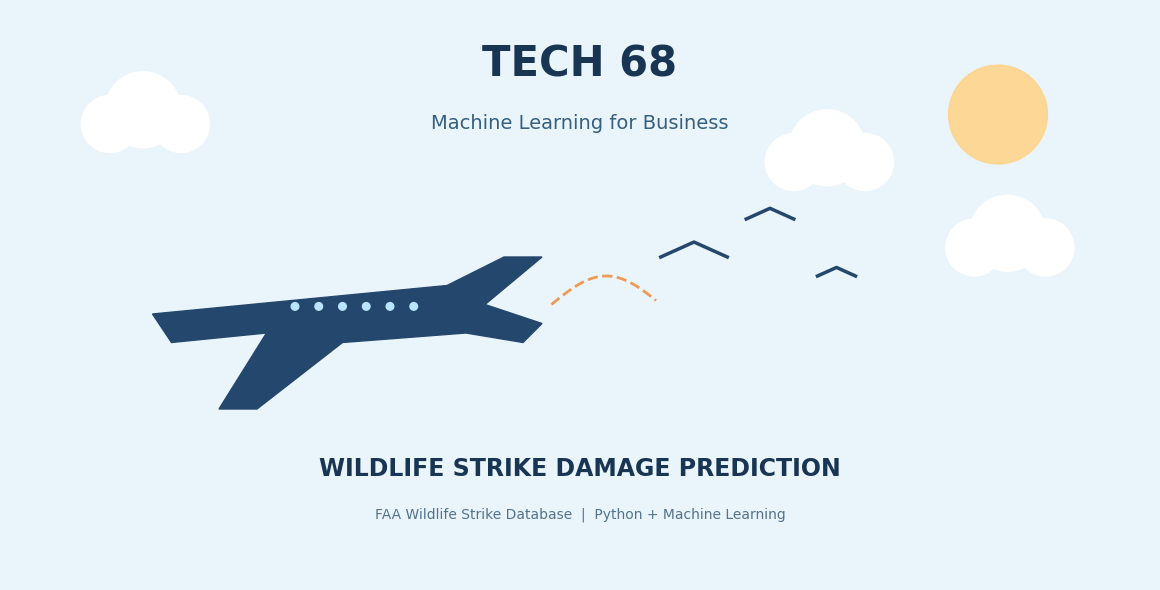

In [152]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Ellipse, Polygon, FancyBboxPatch
import numpy as np

fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor("#eaf4fb")
ax.set_facecolor("#eaf4fb")

# Sky and sun
ax.add_patch(Circle((10.4, 4.9), 0.52, color="#ffd48a", alpha=0.9))

# Clouds
for x, y in [(1.4, 4.8), (8.6, 4.4), (10.5, 3.5)]:
    for dx, dy, r in [(-0.35, 0, 0.3), (0, 0.15, 0.4), (0.4, 0, 0.3)]:
        ax.add_patch(Circle((x + dx, y + dy), r, color="white"))

# Airplane silhouette
plane = np.array([
    [1.5, 2.8], [4.6, 3.1], [5.2, 3.4],
    [5.6, 3.4], [5.0, 2.9], [5.6, 2.7],
    [5.4, 2.5], [4.8, 2.6], [3.5, 2.5],
    [2.6, 1.8], [2.2, 1.8], [2.7, 2.6],
    [1.7, 2.5]
])
ax.add_patch(Polygon(plane, closed=True, color="#24476d"))

# Plane windows
for x in np.arange(3.0, 4.5, 0.25):
    ax.add_patch(Circle((x, 2.88), 0.04, color="#b8e5ff"))

# Flying birds
for x, y, size in [(7.2, 3.4, 0.35), (8.0, 3.8, 0.25), (8.7, 3.2, 0.2)]:
    ax.plot([x-size, x, x+size],
            [y, y+size*0.45, y],
            color="#24476d", linewidth=2.5)

# Flight path
t = np.linspace(0, 1, 70)
ax.plot(5.7 + 1.1*t, 2.9 + 0.3*np.sin(3*t),
        "--", color="#ee9b55", linewidth=2)

# Text
ax.text(6, 5.3, "TECH 68", ha="center",
        fontsize=30, weight="bold", color="#183653")

ax.text(6, 4.75, "Machine Learning for Business",
        ha="center", fontsize=14, color="#365f80")

ax.text(6, 1.1, "WILDLIFE STRIKE DAMAGE PREDICTION",
        ha="center", fontsize=17, weight="bold", color="#183653")

ax.text(6, 0.65, "FAA Wildlife Strike Database  |  Python + Machine Learning",
        ha="center", fontsize=10, color="#52748c")

ax.set_xlim(0, 12)
ax.set_ylim(0, 6)
ax.set_aspect("equal")
ax.axis("off")

plt.tight_layout()
plt.show()